# 05 — Visual retrieval, end to end (E6): ColQwen2 pages against OCR + BM25 pages

> **Status: complete and frozen.** The specification `experiments/specs/e6_visual_retrieval_answering_v1.json` was frozen on 2026-11-23 (ceiling USD 5.60, retries included). The approved smoke and full runs finished on 2026-11-24 for USD 3.72 in all. They are frozen, byte for byte, in `experiments/frozen/e6/` with an independent audit. **Verdict: `adopt_visual_retrieval`** (section 7). By default this notebook makes **no API call** and loads **no visual model**: it re-evaluates the frozen run.

**Objective.** Find out whether the pages ColQwen2 retrieves lead GPT-4o-mini to **more correct answers** than the pages the application's OCR + BM25 retrieves. The test uses E5's held-out questions, with everything else held fixed. The answer decides which retriever the application uses by default.

| | |
|---|---|
| **Input** | **Spec:** `experiments/specs/e6_visual_retrieval_answering_v1.json`.<br>**E5 (frozen, `experiments/frozen/e5/`):** the held-out set and its rankings.<br>**Notebook 04:** the held-out page text, 768-px renders and cached ColQwen2 embeddings (`data/processed/mmlongbench_doc/e5/`, `data/cache/e5/`).<br>**Notebook 00:** `questions.parquet` and the development 768-px renders.<br>**E4 (frozen, `experiments/frozen/e4/`):** used to show that the reader rebuilt here is the application's.<br>**Paid modes only:** `OPENAI_API_KEY`. |
| **Output** | **Offline:** `data/processed/mmlongbench_doc/e6/{design.json, request_plan.csv, cost_plan.csv, planning_simulation.csv}`.<br>**Paid modes:** one new, immutable directory `experiments/runs/e6/<run-id>/` per invocation.<br>**Evaluation (default: the frozen run):** `data/processed/mmlongbench_doc/e6/{evaluation_summary.json, per_question.csv}`, equal byte for byte to `experiments/frozen/e6/tables/`.<br>Never writes to `experiments/frozen/`. |
| **Next** | The application phase, with ColQwen2 as the default retriever and OCR + BM25 as the fallback. Changing `src/visualdoc/` needs the owner's separate approval (AGENTS.md). |

## Method

### 1. Why E6, and why measure answers rather than evidence

**E5 measured evidence.** After the context guard, ColQwen2's pages hold an annotated evidence page for 86 of the 101 held-out questions; BM25's hold one for 66. Evidence recall rises from 0.526 to 0.721.

**E4 showed that evidence is not an answer.** Given exactly the evidence pages, the same reader answers only 17 of 37 development questions.

So whether E5's evidence gain survives the reader is an open empirical question. It is also the question the application needs answered.

### 2. Design: one reader, two page lists

| arm | pages sent (768 px, `mmlb-image-v1`, GPT-4o-mini, temperature 0) | role |
|---|---|---|
| `A` | OCR + BM25 top 5 → context guard (the application as shipped) | control |
| `V` | ColQwen2 v1.0 top 5 → the same guard | treatment |

- **Only the page list differs.** The prompt, header, page tags, images, parameters, guard, parser and scorer are identical in both arms.
- **Request length is matched.** The guard keeps 4 pages for 105 questions and 3 for 13, in **both** arms.
- **One session, balanced order.** All 118 held-out questions are sent in each arm, as adjacent A/V pairs: 59 pairs open with A and 59 with V. Drift and prompt-cache state therefore affect both arms alike.
- **ColQwen2 is neither run nor integrated here.** V's pages come from E5's frozen rankings. Section 1 re-derives them from E5's cached embeddings with NumPy (MaxSim), to show they reproduce without the model.
- **The application is not imported** (AGENTS.md). Section 2 rebuilds the reader and checks it against what the application sent in E4: 96 request fingerprints and 96 parsed replies.

### 3. Primary metric and estimand

For question $i$ and arm $a$, let $c_{i,a} = 1[\text{score}_{i,a} > 0]$, using the frozen MMLongBench-Doc scorer. On the $n = 102$ answerable questions:

$$\Delta = \frac{1}{n}\sum_{i} \big(c_{i,V} - c_{i,A}\big).$$

Questions are not independent: they cluster in 14 documents, with 4–16 questions each. So both the interval and the test work on documents. Let $D_d = \sum_{i \in d}(c_{i,V}-c_{i,A})$ be document $d$'s summed difference and $n_d$ its number of questions.

- **Cluster bootstrap.** Draw 14 documents with replacement and compute $\Delta^* = \sum D_{d^*} / \sum n_{d^*}$; repeat 10,000 times. The one-sided 95 % lower bound is the 5th percentile.
- **Exact sign-flip test.** Under $H_0$ the arm labels are exchangeable within a document, so $D_d$ and $-D_d$ are equally likely. Enumerate all $2^{14} = 16{,}384$ sign vectors $s$:

$$p = \frac{\#\{s : \sum_d s_d D_d \ge \sum_d D_d\}}{2^{14}}.$$

### 4. Decision rule (frozen in the spec before any reply)

| verdict | condition | application action |
|---|---|---|
| `adopt_visual_retrieval` | all four accuracy criteria and both guardrails hold (listed below) | ColQwen2 becomes the default retriever in the application phase (separate approval); BM25 is kept as the fallback |
| `visual_gain_with_regression` | the four accuracy criteria hold, but a guardrail fails | keep BM25; the owner weighs the trade-off |
| `visual_worse` | $\Delta \le -0.05$ and the two-sided 95 % upper bound < 0 | keep BM25 |
| `no_meaningful_difference` | the two-sided 95 % interval lies inside (−0.05, +0.05) | keep BM25 |
| `inconclusive` | anything else | keep BM25 and build the application |

**Accuracy criteria:**
1. $\Delta \ge 0.05$.
2. The bootstrap 5th percentile is above 0.
3. The one-sided sign-flip $p \le 0.05$.
4. Broken ≤ fixed / 2.

**Guardrails:**
- **G1:** correct abstentions on the 16 unanswerable questions, V ≥ A − 2.
- **G2:** citation validity, V − A ≥ −0.05.

**Why one-sided.** E5 fixed the direction before any E6 reply, and "V worse" and "V no better" lead to the same action.

**Statistical evidence is not the deployment decision.** Each verdict carries two pre-registered texts:
- a **statistical reading**: what E6 shows about this population;
- a **deployment action**: what the application does next.

For every verdict except `adopt_visual_retrieval`, the action is to keep OCR + BM25 as the default. That is a product default under uncertainty, chosen because BM25 needs no model and indexes in milliseconds. In particular, `inconclusive` reads "neither established nor excluded". It is **not** a finding that ColQwen2 is ineffective, and E5's evidence-level result stands.

**What to expect.** Section 5 shows what this rule can detect with 102 questions in 14 documents. **An inconclusive result is likely.** It means "not shown", not "no effect".

### 5. Secondary metrics (descriptive; only G1 and G2 enter the rule)

- **Citations:** citation validity, and grounded citations (an answer that cites an annotated evidence page).
- **Abstention:** correct abstention, and false abstention split by whether evidence was supplied.
- **Latency:** API latency (measured here); retrieval and indexing latency (from E5's frozen measurements).
- **Cost:** billed tokens and list-price cost.
- **Efficiency, reported beside answer quality** (from E5's measurements, per held-out document): ColQwen2's indexing time and embedding storage, its model size and memory, against BM25's.

**Population.** E6's 102 answerable questions are E5's 101 evidence questions plus mmlb-0599. That question is answerable, but its evidence-page list is empty in the benchmark. It counts in the primary (accuracy needs only the reference answer) and in no evidence-based metric. Section 1 checks this.

### 6. Run modes (`VISUALDOC_E6_MODE`)

| mode | API calls | use |
|---|---:|---|
| `offline` (default) | 0 | everything in sections 1–7 except sending |
| `smoke` | 2 | the A and V requests of the largest question: snapshot, JSON contract, token accounting |
| `full` | 2 + 236 | the smoke pair again (never scored), then 118 adjacent A/V pairs |

Each paid mode needs all of the following:
- the frozen spec, with an approved ceiling (proposed: USD 5.60 cumulative, retries included);
- the spec and this notebook's code committed;
- the owner's explicit approval of that stage.

In [1]:
# E6 setup: paths, the specification, the run mode and the inputs. Nothing here depends on an E6 outcome.
from collections import Counter, deque
from datetime import datetime, timezone
from itertools import product
from math import ceil, comb, isclose, log
from pathlib import Path
import ast
import base64
import hashlib
import json
import os
import re
import subprocess
import tempfile
import time
import uuid

import httpx
import matplotlib.pyplot as plt
import numpy as np
import openai
import pandas as pd
import tiktoken
from IPython.display import display
from openai.types.chat import ChatCompletion

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)


def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not find the repository root")


PROJECT_ROOT = find_project_root()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "mmlongbench_doc"
E5_DIR = PROCESSED_DIR / "e5"
E6_DIR = PROCESSED_DIR / "e6"
FROZEN_E4_DIR = PROJECT_ROOT / "experiments" / "frozen" / "e4"
FROZEN_E4_RUN = FROZEN_E4_DIR / "run_20261123T000625940289Z_15119ec0_full"
FROZEN_E5_DIR = PROJECT_ROOT / "experiments" / "frozen" / "e5"
E5_SPEC_RELPATH = "experiments/specs/e5_visual_retrieval_v1.json"
SPEC_RELPATH = "experiments/specs/e6_visual_retrieval_answering_v1.json"
NOTEBOOK_RELPATH = "notebooks/05_visual_retrieval_answering.ipynb"
RUNS_DIR = PROJECT_ROOT / "experiments" / "runs" / "e6"

REQUIRED_INPUTS = {
    PROCESSED_DIR / "questions.parquet": "run 00_document_processing",
    PROCESSED_DIR / "render_manifest_e1.csv": "run 00_document_processing",
    E5_DIR / "heldout_pages.parquet": "run 04_visual_retrieval",
    E5_DIR / "render_manifest_heldout.csv": "run 04_visual_retrieval",
    PROJECT_ROOT / SPEC_RELPATH: "the E6 specification is tracked in git: restore it",
    PROJECT_ROOT / E5_SPEC_RELPATH: "the E5 specification is tracked in git: restore it",
    FROZEN_E5_DIR / "SHA256SUMS": "the frozen E5 result is tracked in git: restore it",
    FROZEN_E4_DIR / "SHA256SUMS": "the frozen E4 result is tracked in git: restore it",
}
missing = [f"{path.relative_to(PROJECT_ROOT)} ({fix})" for path, fix in REQUIRED_INPUTS.items() if not path.is_file()]
assert not missing, "E6 inputs missing:\n  " + "\n  ".join(missing)
E6_DIR.mkdir(parents=True, exist_ok=True)

SPEC_BYTES = (PROJECT_ROOT / SPEC_RELPATH).read_bytes()
SPEC_SHA256 = hashlib.sha256(SPEC_BYTES).hexdigest()
SPEC = json.loads(SPEC_BYTES)
assert SPEC["spec_id"] == "e6-visual-retrieval-answering-v1"
SPEC_FROZEN = SPEC["status"] == "frozen-before-live-execution" and bool(SPEC.get("frozen_at"))
E6_MODE = os.getenv("VISUALDOC_E6_MODE", "offline")
assert E6_MODE in {"offline", "smoke", "full"}, "VISUALDOC_E6_MODE must be offline, smoke or full"
MODEL, READER, EXECUTION, BUDGET, POP, RULE = (SPEC[k] for k in ("model", "reader", "execution", "budget", "population", "decision_rule"))
ARMS = {name: arm["label"] for name, arm in SPEC["design"]["arms"].items()}
assert list(ARMS) == ["A", "V"]
PRICE = {"input": MODEL["input_usd_per_1m_tokens"] / 1e6, "output": MODEL["output_usd_per_1m_tokens"] / 1e6}

display(pd.Series({
    "specification": f"{SPEC['spec_id']} (sha256 {SPEC_SHA256[:12]})",
    "status": SPEC["status"] + ("" if SPEC_FROZEN else " (not frozen: the paid modes are closed)"),
    "approved budget (USD)": f"{BUDGET['approved_ceiling_usd']} (proposed {BUDGET['proposed_ceiling_usd']}, retries included)",
    "E6 mode": E6_MODE,
    "reader": f"{MODEL['requested_snapshot']} (shutdown 2027-01-14), prompt {READER['system_prompt_version']}, 768-px images",
    "arms": "; ".join(f"{k}: {v}" for k, v in ARMS.items()),
}, name="E6").to_frame())

,E6
specification,e6-visual-retrieval-answering-v1 (sha256 23e02872535f)
status,frozen-before-live-execution
approved budget (USD),"5.6 (proposed 5.6, retries included)"
E6 mode,offline
reader,"gpt-4o-mini-2024-07-18 (shutdown 2027-01-14), prompt mml..."
arms,A: application retriever: OCR + BM25; V: visual retrieve...


## 1. Inputs: E5's held-out questions, rankings and embeddings

E6 reuses E5's held-out set and E5's two rankings, rather than producing new ones.

1. The frozen E5 copy is checked byte for byte against its checksums.
2. Both rankings are then re-derived here: BM25 from E5's page text, and ColQwen2 from E5's cached embeddings.

V's pages therefore rest on data this notebook can reproduce, not on a file it has to trust. Only the question string and the document ever reach a ranking function. The annotations stay in a separate table.

In [2]:
# The frozen copies this notebook relies on are checked byte for byte, and the E5 spec must equal its freeze commit.
def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def verify_sha256sums(folder):
    entries = [line.split(maxsplit=1) for line in (folder / "SHA256SUMS").read_text().splitlines() if line.strip()]
    return {name: (folder / name).is_file() and sha256_bytes((folder / name).read_bytes()) == digest for digest, name in entries}


def git_show_bytes(commit, relpath):
    shown = subprocess.run(["git", "show", f"{commit}:{relpath}"], cwd=PROJECT_ROOT, capture_output=True)
    return shown.stdout if shown.returncode == 0 else None


def read_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]


for folder in (FROZEN_E5_DIR, FROZEN_E4_DIR):
    checksums = verify_sha256sums(folder)
    assert checksums and all(checksums.values()), f"{folder.relative_to(PROJECT_ROOT)} differs from its SHA256SUMS: {[k for k, ok in checksums.items() if not ok]}"
e5_summary = json.loads((FROZEN_E5_DIR / "tables" / "summary.json").read_text())
E5_SPEC_BYTES = (PROJECT_ROOT / E5_SPEC_RELPATH).read_bytes()
assert git_show_bytes(e5_summary["spec_freeze_commit"], E5_SPEC_RELPATH) == E5_SPEC_BYTES == (FROZEN_E5_DIR / "spec_snapshot.json").read_bytes(), \
    "the E5 spec differs from its freeze commit or from the frozen snapshot"
E5_SPEC = json.loads(E5_SPEC_BYTES)
assert e5_summary["decision"]["verdict"] == "visual_improves_evidence"

# The held-out population: every question about the 14 documents E5 selected.
HELDOUT_DOCS = E5_SPEC["populations"]["held_out"]["selected_documents"]
assert HELDOUT_DOCS == POP["documents"]
questions = pd.read_parquet(PROCESSED_DIR / "questions.parquet")
questions["evidence_pages"] = questions["evidence_pages"].map(lambda values: [int(v) for v in values])
questions["evidence_sources"] = questions["evidence_sources"].map(list)
question_of = questions.set_index("qid")["question"]
held = questions[questions["doc_id"].isin(HELDOUT_DOCS)].sort_values("qid").reset_index(drop=True)
held_pages = pd.read_parquet(E5_DIR / "heldout_pages.parquet")
assert all(sorted(g["page"]) == list(range(1, len(g) + 1)) for _, g in held_pages.groupby("doc_id")), "held-out page table is incomplete: rerun 04"
PAGE_COUNT = held_pages.groupby("doc_id").size()
held["evidence_population"] = [bool(r.answerable) and bool(r.evidence_pages) and min(r.evidence_pages) >= 1 and max(r.evidence_pages) <= PAGE_COUNT[r.doc_id]
                               for r in held.itertuples()]
QIDS = held["qid"].tolist()
ANSWERABLE = held.loc[held["answerable"], "qid"].tolist()
UNANSWERABLE = held.loc[~held["answerable"], "qid"].tolist()
EVIDENCE_QIDS = held.loc[held["evidence_population"], "qid"].tolist()
assert (len(QIDS), len(ANSWERABLE), len(UNANSWERABLE), len(EVIDENCE_QIDS)) == (POP["questions"], POP["answerable"], POP["unanswerable"], POP["evidence_population"])
assert sorted(set(ANSWERABLE) - set(EVIDENCE_QIDS)) == POP["answerable_without_evidence_pages"]
assert not held["in_subset"].any(), "a held-out question is in the development subset"
held_idx = held.set_index("qid")
doc_of = held_idx["doc_id"]

# E5's evidence population and frozen per-question table describe the same questions and annotations.
frozen_e5_held = pd.read_csv(FROZEN_E5_DIR / "tables" / "per_question.csv").query("population == 'held-out'").set_index("qid")
assert sorted(frozen_e5_held.index) == EVIDENCE_QIDS
assert all(json.loads(frozen_e5_held.loc[q, "evidence_pages"]) == held_idx.loc[q, "evidence_pages"] for q in EVIDENCE_QIDS)

# The frozen rankings of arms A and V: a full permutation of each PDF's pages, for every held-out question.
rankings = pd.read_parquet(FROZEN_E5_DIR / "tables" / "rankings.parquet")
rankings = rankings[(rankings["population"] == "held-out") & rankings["arm"].isin(list(ARMS))]
RANKING = {(r.qid, r.arm): [int(p) for p in r.pages] for r in rankings.itertuples()}
RANKING_SCORE = {(r.qid, r.arm): np.asarray(r.scores, dtype=np.float64) for r in rankings.itertuples()}
assert set(RANKING) == {(q, a) for q in QIDS for a in ARMS}
assert all(sorted(pages) == list(range(1, PAGE_COUNT[doc_of[q]] + 1)) for (q, _), pages in RANKING.items())

# E5's 101 evidence questions versus E6's 102 answerable questions: the single difference, named and checked against the spec.
reconciliation = POP["reconciliation_101_vs_102"]
answerable_without_evidence = sorted(set(ANSWERABLE) - set(EVIDENCE_QIDS))
assert answerable_without_evidence == POP["answerable_without_evidence_pages"] == ["mmlb-0599"]
assert held_idx.loc["mmlb-0599", "evidence_pages"] == [] and held_idx.loc["mmlb-0599", "doc_id"] in reconciliation["mmlb-0599"]
assert held_idx.loc["mmlb-0599", "answer_format"] in reconciliation["mmlb-0599"] and all(("mmlb-0599", a) in RANKING for a in ARMS)
assert set(EVIDENCE_QIDS) <= set(ANSWERABLE) and len(ANSWERABLE) == len(EVIDENCE_QIDS) + len(answerable_without_evidence)
assert len(QIDS) == len(ANSWERABLE) + len(UNANSWERABLE)
display(pd.DataFrame([
    ("held-out questions (E5's 14 documents)", len(QIDS), "every question is sent in both arms"),
    ("unanswerable", len(UNANSWERABLE), "abstention metrics, guardrail G1"),
    ("answerable = E6 primary population", len(ANSWERABLE), "accuracy needs only the reference answer"),
    ("  with at least one evidence page = E5's evidence population", len(EVIDENCE_QIDS), "strata, grounded citations, 101-question sensitivity"),
    ("  without evidence pages (mmlb-0599: List answer, evidence_pages [])", len(answerable_without_evidence),
     "in the primary; group 'no annotated evidence'; moves delta by at most 1/102"),
], columns=["set", "questions", "role in E6"]).set_index("set"))

# The only table requests are built from: no evidence page, reference answer, answer format or answerability.
retrieval_input = held[["qid", "doc_id", "question"]].copy()

documents = pd.DataFrame({
    "pages": PAGE_COUNT[HELDOUT_DOCS], "questions": held.groupby("doc_id").size()[HELDOUT_DOCS],
    "answerable": held.groupby("doc_id")["answerable"].sum()[HELDOUT_DOCS],
    "evidence population": held.groupby("doc_id")["evidence_population"].sum()[HELDOUT_DOCS]}).astype(int)
documents.index = documents.index.str.slice(0, 44)
print(f"Frozen E4 and E5 copies equal their SHA256SUMS; the E5 spec equals its freeze commit {e5_summary['spec_freeze_commit'][:7]}.")
print(f"Held-out: {len(QIDS)} questions ({len(ANSWERABLE)} answerable, {len(UNANSWERABLE)} unanswerable) in {len(HELDOUT_DOCS)} documents, "
      f"{int(PAGE_COUNT.sum())} pages; evidence population {len(EVIDENCE_QIDS)} (answerable without annotated evidence: "
      f"{POP['answerable_without_evidence_pages']}). Frozen rankings: {len(RANKING)} (question, arm) pairs.")
display(documents)

,questions,role in E6
set,,
held-out questions (E5's 14 documents),118,every question is sent in both arms
unanswerable,16,"abstention metrics, guardrail G1"
answerable = E6 primary population,102,accuracy needs only the reference answer
with at least one evidence page = E5's evidence population,101,"strata, grounded citations, 101-question sensitivity"
"without evidence pages (mmlb-0599: List answer, evidence_pages [])",1,in the primary; group 'no annotated evidence'; moves del...


Frozen E4 and E5 copies equal their SHA256SUMS; the E5 spec equals its freeze commit 073d0a4.
Held-out: 118 questions (102 answerable, 16 unanswerable) in 14 documents, 647 pages; evidence population 101 (answerable without annotated evidence: ['mmlb-0599']). Frozen rankings: 236 (question, arm) pairs.


,pages,questions,answerable,evidence population
doc_id,,,,
2312.10997v5.pdf,21,7,6,6
2310.05634v2.pdf,24,7,6,6
e639029d16094ea71d964e2fb953952b.pdf,20,7,6,6
3276a5b991c49cf5f9a4af0f7d6fce67.pdf,16,8,7,6
2021-Apple-Catalog.pdf,55,4,3,3
NUS-Business-School-BBA-Brochure-2024.pdf,24,6,5,5
COSTCO_2021_10K.pdf,76,16,16,16
AMAZON_2017_10K.pdf,85,15,15,15
SAO-StudentSupport_Guidebook-Content.pdf,44,5,5,5


In [3]:
# Arm A, re-derived: BM25 (notebook 01's definition, as in the application) over E5's held-out page text.
# score(q, d) = sum over query terms t in d of idf(t) * f(t, d) * (k1 + 1) / (f(t, d) + k1 * (1 - b + b * |d| / avgdl)),
# idf(t) = ln(1 + (N - n_t + 0.5) / (n_t + 0.5)); lower-cased [a-z0-9]+ tokens; ties broken by page number.
BM25_K1, BM25_B = 1.5, 0.75
assert "k1 1.5, b 0.75" in E5_SPEC["arms"]["A_bm25"]["ranking"]
TOKEN_PATTERN = re.compile(r"[a-z0-9]+")


def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())


def build_bm25_index(page_texts):
    tokens = {page: tokenize(text) for page, text in page_texts.items()}
    document_frequency = Counter(token for page_tokens in tokens.values() for token in set(page_tokens))
    n_pages = len(tokens)
    return {"term_counts": {page: Counter(t) for page, t in tokens.items()}, "lengths": {page: len(t) for page, t in tokens.items()},
            "avgdl": float(np.mean([len(t) for t in tokens.values()])),
            "idf": {token: log(1 + (n_pages - n_t + 0.5) / (n_t + 0.5)) for token, n_t in document_frequency.items()}}


def bm25_rank(index, query, k1=BM25_K1, b=BM25_B):
    terms = set(tokenize(query))
    scored = []
    for page, counts in index["term_counts"].items():
        length_factor = k1 * (1 - b + b * index["lengths"][page] / max(index["avgdl"], 1.0))
        scored.append((page, sum(index["idf"][t] * counts[t] * (k1 + 1) / (counts[t] + length_factor) for t in terms if counts[t])))
    return sorted(scored, key=lambda item: (-item[1], item[0]))


started = time.perf_counter()
bm25_indexes = {doc_id: build_bm25_index(dict(zip(group["page"], group["text"]))) for doc_id, group in held_pages.groupby("doc_id")}
bm25_index_ms_per_page = 1e3 * (time.perf_counter() - started) / len(held_pages)
started = time.perf_counter()
A_rebuilt = {row.qid: bm25_rank(bm25_indexes[row.doc_id], row.question) for row in retrieval_input.itertuples()}
bm25_query_ms = 1e3 * (time.perf_counter() - started) / len(retrieval_input)
A_mismatch = [q for q in QIDS if [p for p, _ in A_rebuilt[q]] != RANKING[(q, "A")]]
A_score_gap = max(np.abs(np.array([s for _, s in A_rebuilt[q]]) - RANKING_SCORE[(q, "A")]).max() for q in QIDS)
assert not A_mismatch and A_score_gap < 1e-4, (A_mismatch[:5], A_score_gap)
print(f"Arm A re-derived: the full BM25 ranking equals E5's frozen ranking for {len(QIDS) - len(A_mismatch)}/{len(QIDS)} questions "
      f"(largest score difference {A_score_gap:.1e}, float32 storage). Index {bm25_index_ms_per_page:.2f} ms per page, query {bm25_query_ms:.2f} ms.")

Arm A re-derived: the full BM25 ranking equals E5's frozen ranking for 118/118 questions (largest score difference 5.0e-07, float32 storage). Index 0.09 ms per page, query 0.48 ms.


In [4]:
# Arm V, re-derived from E5's cached ColQwen2 embeddings with NumPy only: no model is loaded and nothing is encoded.
e5_context = json.loads((FROZEN_E5_DIR / "tables" / "run_context.json").read_text())
ENCODER_CONFIG = e5_context["encoder_config"]
CONFIG_HASH = sha256_bytes(json.dumps(ENCODER_CONFIG, sort_keys=True).encode())[:12]
checkpoint = E5_SPEC["arms"]["V_colqwen2"]["checkpoint"]
EMBEDDING_DIR = PROJECT_ROOT / "data" / "cache" / "e5" / f"{checkpoint['repo'].split('/')[-1]}@{checkpoint['revision'][:12]}" / CONFIG_HASH
assert (EMBEDDING_DIR / "config.json").is_file(), f"E5's embedding cache is missing ({EMBEDDING_DIR.relative_to(PROJECT_ROOT)}): run 04_visual_retrieval"
assert json.loads((EMBEDDING_DIR / "config.json").read_text()) == ENCODER_CONFIG, "the cached embeddings were made with another encoder configuration"


def load_bf16_safetensors(path):
    # A safetensors file is an 8-byte little-endian header length, a JSON header (dtype, shape, byte offsets), then raw tensors.
    # bfloat16 is the upper 16 bits of a float32, so shifting its bits back up by 16 converts it exactly.
    raw = Path(path).read_bytes()
    header_length = int.from_bytes(raw[:8], "little")
    header = json.loads(raw[8:8 + header_length])
    body = raw[8 + header_length:]
    tensors = {}
    for name, info in header.items():
        if name == "__metadata__":
            continue
        assert info["dtype"] == "BF16", f"{Path(path).name}: {name} is {info['dtype']}, not BF16"
        start, end = info["data_offsets"]
        bits = np.frombuffer(body[start:end], dtype="<u2").astype(np.uint32) << 16
        tensors[name] = bits.view(np.float32).reshape(info["shape"])
    return tensors


def maxsim(query, page):
    # Late interaction: each query vector's best dot product with any page vector, summed over the query vectors.
    return float((query @ page.T).max(axis=1).sum())


held_manifest = pd.read_csv(E5_DIR / "render_manifest_heldout.csv")
frozen_manifest = pd.read_csv(FROZEN_E5_DIR / "tables" / "render_manifest_heldout.csv")
manifest_columns = ["doc_id", "page", "width_px", "height_px", "sha256"]
assert held_manifest[manifest_columns].equals(frozen_manifest[manifest_columns]), "held-out renders differ from the frozen E5 manifest: rerun 04"
held_manifest = held_manifest.set_index(["doc_id", "page"])
page_embedding_path = lambda doc_id, page: EMBEDDING_DIR / "pages" / f"{held_manifest.loc[(doc_id, page), 'sha256']}.safetensors"
query_embedding_path = lambda question: EMBEDDING_DIR / "queries" / f"{sha256_bytes(question.encode())}.safetensors"
missing_embeddings = [str(p) for p in [*(page_embedding_path(d, p) for d, p in held_manifest.index), *(query_embedding_path(q) for q in retrieval_input["question"])]
                      if not p.is_file()]
assert not missing_embeddings, f"{len(missing_embeddings)} cached embeddings missing: run 04_visual_retrieval"

# Shown once by hand, on the first held-out question: Q (query vectors x 128) against each page's D (page vectors x 128).
demo = retrieval_input.iloc[0]
Q = load_bf16_safetensors(query_embedding_path(demo["question"]))["embedding"]
D = load_bf16_safetensors(page_embedding_path(demo["doc_id"], RANKING[(demo["qid"], "V")][0]))["embedding"]
similarity = Q @ D.T
print(f"{demo['qid']}: Q {Q.shape}, its best page p.{RANKING[(demo['qid'], 'V')][0]} D {D.shape}, similarity {similarity.shape}; "
      f"vectors unit-norm: {np.allclose(np.linalg.norm(Q, axis=1), 1, atol=1e-2)}; s(q, d) = sum of row maxima = {similarity.max(axis=1).sum():.3f}")

V_rebuilt, V_score_ms = {}, []
for doc_id, doc_qids in retrieval_input.groupby("doc_id")["qid"]:
    page_vectors = {p: load_bf16_safetensors(page_embedding_path(doc_id, p))["embedding"] for p in range(1, PAGE_COUNT[doc_id] + 1)}
    for qid in doc_qids:
        query = load_bf16_safetensors(query_embedding_path(question_of[qid]))["embedding"]
        started = time.perf_counter()
        V_rebuilt[qid] = sorted(((p, maxsim(query, d)) for p, d in page_vectors.items()), key=lambda item: (-item[1], item[0]))
        V_score_ms.append(1e3 * (time.perf_counter() - started))
V_mismatch = [q for q in QIDS if [p for p, _ in V_rebuilt[q]] != RANKING[(q, "V")]]
V_score_gap = max(np.abs(np.array([s for _, s in V_rebuilt[q]]) - RANKING_SCORE[(q, "V")]).max() for q in QIDS)
assert not V_mismatch and V_score_gap < 1e-3, (V_mismatch[:5], V_score_gap)
print(f"Arm V re-derived from {len(held_manifest)} cached page embeddings and {len(retrieval_input)} query embedding files: the full MaxSim ranking equals "
      f"E5's frozen ranking for {len(QIDS) - len(V_mismatch)}/{len(QIDS)} questions (largest score difference {V_score_gap:.1e}; "
      f"E5 summed in torch, here in NumPy). Scoring from cache: {np.median(V_score_ms):.1f} ms per question (median).")

mmlb-0042: Q (31, 128), its best page p.12 D (779, 128), similarity (31, 779); vectors unit-norm: True; s(q, d) = sum of row maxima = 23.620


Arm V re-derived from 647 cached page embeddings and 118 query embedding files: the full MaxSim ranking equals E5's frozen ranking for 118/118 questions (largest score difference 6.0e-06; E5 summed in torch, here in NumPy). Scoring from cache: 1.5 ms per question (median).


In [5]:
# What ColQwen2 costs to run, measured in E5 on the held-out documents (fanless Apple M1, MPS, bf16): reported beside answer quality
# in section 7 so that an integration decision weighs efficiency. Descriptive only; never part of the verdict. No model is run here.
E5_COST = e5_context["cost"]
encoding_log = pd.read_csv(FROZEN_E5_DIR / "tables" / "encoding_log.csv")
image_seconds = encoding_log[encoding_log["pass"].isin(["vision", "language"])].groupby(["key", "pass"])["seconds"].sum().unstack()
held_images = held_manifest.reset_index()
assert set(held_images["sha256"]) <= set(image_seconds.index), "a held-out page image has no E5 encoding time"
assert (image_seconds.loc[held_images["sha256"].unique()].notna().all(axis=None)), "a held-out image lacks one of the two passes"
held_images["embedding_bytes"] = [page_embedding_path(d, p).stat().st_size for d, p in zip(held_images["doc_id"], held_images["page"])]


def document_efficiency(group):
    # A document is indexed once per distinct page image (E5 encodes identical images once).
    distinct = group.drop_duplicates("sha256")
    seconds = image_seconds.loc[distinct["sha256"]].sum(axis=1)
    return pd.Series({"pages": len(group), "distinct page images": len(distinct), "ColQwen2 indexing, min (measured)": seconds.sum() / 60,
                      "ColQwen2 s per page image (median)": seconds.median(), "ColQwen2 embeddings, MB": distinct["embedding_bytes"].sum() / 1e6})


EFFICIENCY_BY_DOC = held_images.groupby("doc_id")[["sha256", "embedding_bytes"]].apply(document_efficiency).loc[sorted(HELDOUT_DOCS)]
all_seconds = image_seconds.loc[held_images["sha256"].unique()].sum(axis=1)
EFFICIENCY = {
    "ColQwen2 indexing, held-out documents (measured)": f"{all_seconds.sum() / 3600:.2f} h for {len(all_seconds)} distinct page images "
                                                        f"({held_images['sha256'].duplicated().sum()} of {len(held_images)} pages repeat an image); "
                                                        f"median {all_seconds.median():.1f} s per image",
    "ColQwen2 indexing, per document (measured)": f"{EFFICIENCY_BY_DOC['ColQwen2 indexing, min (measured)'].min():.1f}-"
                                                  f"{EFFICIENCY_BY_DOC['ColQwen2 indexing, min (measured)'].max():.1f} min for {int(EFFICIENCY_BY_DOC['pages'].min())}-"
                                                  f"{int(EFFICIENCY_BY_DOC['pages'].max())} pages",
    "ColQwen2 embedding storage, held-out documents": f"{held_images.drop_duplicates('sha256')['embedding_bytes'].sum() / 1e6:.1f} MB "
                                                      f"(median {held_images['embedding_bytes'].median() / 1e3:.0f} KB per page, bf16)",
    "ColQwen2 query encoding + scoring, per question": f"{E5_COST['query encoding, s per query (median)']} s + {E5_COST['MaxSim scoring, ms per question (all pages of its PDF)']} ms",
    "ColQwen2 model": f"weights {E5_COST['model weights on disk']} on disk; peak GPU memory {E5_COST['peak MPS driver memory, GB (vision / language)'].split('/')[-1].strip()} GB",
    "BM25 (application)": f"index {E5_COST['BM25: index, ms per page / query, ms'].split('/')[0].strip()} ms per page, query "
                          f"{E5_COST['BM25: index, ms per page / query, ms'].split('/')[1].strip()} ms; text extraction "
                          f"{E5_COST['baseline text: held-out extraction incl. OCR, s per page']} s per page; no model",
    "measurement conditions": "E5, 2026-11-23, one fanless Apple M1 (8 GB), two sessions; a faster GPU would index far faster; not re-measured in E6",
}
display(pd.Series(EFFICIENCY, name="efficiency (E5 measurements)").to_frame())
display(EFFICIENCY_BY_DOC.set_axis(EFFICIENCY_BY_DOC.index.str.slice(0, 40)).round(1))

,efficiency (E5 measurements)
"ColQwen2 indexing, held-out documents (measured)",2.19 h for 642 distinct page images (5 of 647 pages repe...
"ColQwen2 indexing, per document (measured)",3.0-19.4 min for 16-85 pages
"ColQwen2 embedding storage, held-out documents","124.2 MB (median 193 KB per page, bf16)"
"ColQwen2 query encoding + scoring, per question",0.16 s + 4.4 ms
ColQwen2 model,weights 4.42 GB on disk; peak GPU memory 3.33 GB
BM25 (application),"index 0.08 ms per page, query 0.13 ms; text extraction 0..."
measurement conditions,"E5, 2026-11-23, one fanless Apple M1 (8 GB), two session..."


,pages,distinct page images,"ColQwen2 indexing, min (measured)",ColQwen2 s per page image (median),"ColQwen2 embeddings, MB"
doc_id,,,,,
11-21-16-Updated-Post-Election-Release.p,45.0,45.0,7.9,9.1,8.7
2021-Apple-Catalog.pdf,55.0,55.0,13.0,13.7,10.6
2310.05634v2.pdf,24.0,24.0,4.7,11.6,4.6
2312.10997v5.pdf,21.0,21.0,4.5,12.4,4.1
3276a5b991c49cf5f9a4af0f7d6fce67.pdf,16.0,16.0,3.9,14.3,3.1
AMAZON_2017_10K.pdf,85.0,85.0,19.4,13.5,16.4
COSTCO_2021_10K.pdf,76.0,76.0,16.6,12.6,14.7
Macbook_air.pdf,76.0,72.0,15.9,12.4,13.6
NUS-Business-School-BBA-Brochure-2024.pd,24.0,24.0,6.2,15.1,4.6


## 2. The reader, rebuilt and checked against what the application sent in E4

Both arms must reach GPT-4o-mini through the application's reader: the same prompt, header, page tags, images, guard and parser. AGENTS.md keeps `src/visualdoc` out of this notebook, so the reader is written out below from its definition. That raises a fair question: is this copy really the application?

The frozen E4 run answers it, because the application itself built and parsed those requests. The copy here must reproduce all of the following:

- the fingerprint (SHA-256 of the request, with image hashes in place of the Base64) of each of the 96 E4 requests;
- their expected and upper-bound prompt tokens;
- the application's parse of each of the 96 replies;
- the 57 page lists E4's context guard kept;
- the citation checks in E4's frozen evaluation.

In [6]:
# The reader as the application defines it (src/visualdoc/answering.py and citations.py at the hashes E4 pinned), written out here.
IMAGE_PROMPT_VERSION = READER["system_prompt_version"]
IMAGE_SYSTEM_PROMPT = """You answer questions about a single PDF document using only the page images provided.
Each page image is preceded by a tag [Page N], where N is the 1-based page number in the PDF.

Return a JSON object with exactly these keys:
  "answer": the shortest complete answer. Use a number (integer or decimal) when the answer is a number,
            and a JSON list when several items are asked for. If the page images do not contain the answer,
            use exactly the string "Not answerable".
  "cited_pages": a list of the page numbers N whose images support the answer ([] if "Not answerable").

Do not use knowledge outside the page images. Do not guess."""
assert sha256_bytes((IMAGE_PROMPT_VERSION + IMAGE_SYSTEM_PROMPT).encode())[:12] == READER["system_prompt_hash"] == "35ff2e8b91f9"
SNAPSHOT = MODEL["requested_snapshot"]
CONTEXT_TOKENS = MODEL["context_window_tokens"]
MAX_OUTPUT_TOKENS = READER["max_completion_tokens"]
FRAMING_TOKENS = READER["framing_token_allowance"]
TOP_K = READER["top_k"]
IMAGE_BASE_TOKENS, IMAGE_TILE_TOKENS = 2_833, 5_667
NOT_ANSWERABLE = "Not answerable"
PNG_SIGNATURE = b"\x89PNG\r\n\x1a\n"
ENCODING = tiktoken.get_encoding("o200k_base")
MESSAGE_OVERHEAD_TOKENS = 9  # chat framing beyond the text tokens (notebook 02 section 5; +1 billed on every frozen image call)


def png_size(png):
    if not isinstance(png, bytes) or not png.startswith(PNG_SIGNATURE) or len(png) < 24:
        raise ValueError("page image is not a PNG")
    return int.from_bytes(png[16:20], "big"), int.from_bytes(png[20:24], "big")


def image_tokens(width, height):
    # GPT-4o-mini, detail high: fit in 2048 x 2048, shrink (never enlarge) the short side to 768, then 2,833 + 5,667 per 512-px tile.
    scale = min(1.0, 2048 / max(width, height))
    width, height = width * scale, height * scale
    short_scale = 768 / min(width, height)
    if short_scale < 1:
        width, height = width * short_scale, height * short_scale
    return IMAGE_BASE_TOKENS + IMAGE_TILE_TOKENS * ceil(round(width, 6) / 512) * ceil(round(height, 6) / 512)


def question_header(question):
    return f"Question: {question}\n\nPage images:"


def page_tag(number):
    return f"[Page {number}]"


def guard(question, ranked_pages, limit=CONTEXT_TOKENS - MAX_OUTPUT_TOKENS):
    # ranked_pages: [(page, png), ...] best first. Keep the longest prefix whose prompt-token bound fits; never reorder.
    total = FRAMING_TOKENS + len(IMAGE_SYSTEM_PROMPT.encode()) + len(question_header(question).encode())
    kept = []
    for number, png in ranked_pages:
        cost = len(page_tag(number).encode()) + image_tokens(*png_size(png))
        if total + cost > limit:
            break
        kept.append((number, png))
        total += cost
    return kept, [number for number, _ in ranked_pages[len(kept):]]


def build_request(question, pages):
    if not str(question).strip():
        raise ValueError("the question is empty")
    if not pages or len({number for number, _ in pages}) != len(pages):
        raise ValueError("at least one page is needed, and no page may be supplied twice")
    content = [{"type": "text", "text": question_header(question)}]
    for number, png in pages:
        png_size(png)
        content += [{"type": "text", "text": page_tag(number)},
                    {"type": "image_url", "image_url": {"url": "data:image/png;base64," + base64.b64encode(png).decode("ascii"), "detail": READER["image_detail"]}}]
    return {"model": SNAPSHOT, "messages": [{"role": "system", "content": IMAGE_SYSTEM_PROMPT}, {"role": "user", "content": content}],
            "response_format": {"type": READER["response_format"]}, "max_completion_tokens": MAX_OUTPUT_TOKENS, "temperature": READER["temperature"]}


def decoded_image(part):
    return base64.b64decode(part["image_url"]["url"].split(",", 1)[1])


def loggable(request):
    # The request with every image replaced by its SHA-256 and size: safe to save, no Base64.
    def strip(part):
        if part.get("type") == "image_url":
            raw = decoded_image(part)
            return {"type": "image", "sha256": sha256_bytes(raw), "bytes": len(raw), "detail": part["image_url"].get("detail")}
        return part

    messages = [{"role": m["role"], "content": m["content"] if isinstance(m["content"], str) else [strip(p) for p in m["content"]]} for m in request["messages"]]
    return {**{key: value for key, value in request.items() if key != "messages"}, "messages": messages}


def request_fingerprint(request):
    return sha256_bytes(json.dumps(loggable(request), sort_keys=True).encode())


def request_parts(request):
    texts, images = [], []
    for message in request["messages"]:
        for part in [{"type": "text", "text": message["content"]}] if isinstance(message["content"], str) else message["content"]:
            if part["type"] == "text":
                texts.append(part["text"])
            elif part["type"] == "image_url":
                png = decoded_image(part)
                width, height = png_size(png)
                images.append({"sha256": sha256_bytes(png), "width_px": width, "height_px": height})
            else:
                raise ValueError(f"unexpected {part['type']!r} part")
    return texts, images


def expected_prompt_tokens(request):
    # The exact expectation: o200k_base tokens of every text + 9 + billed image tokens.
    texts, images = request_parts(request)
    return sum(len(ENCODING.encode(t)) for t in texts) + MESSAGE_OVERHEAD_TOKENS + sum(image_tokens(i["width_px"], i["height_px"]) for i in images)


def prompt_token_bound(request):
    # The application's upper bound (no tokenizer): byte-level BPE never needs more tokens than UTF-8 bytes; + 100 framing.
    texts, images = request_parts(request)
    return FRAMING_TOKENS + sum(len(t.encode("utf-8")) for t in texts) + sum(image_tokens(i["width_px"], i["height_px"]) for i in images)


def call_cost_upper(bound):
    return bound * PRICE["input"] + MAX_OUTPUT_TOKENS * PRICE["output"]


def check_request(request, max_cost_usd=READER["max_request_cost_usd"]):
    # The application's pre-call check: raises (nothing is sent) on an unknown model, unbounded output, context overflow or cost.
    if request.get("model") != SNAPSHOT:
        raise ValueError(f"no context size or price is known for model {request.get('model')!r}")
    output = request.get("max_completion_tokens")
    if not isinstance(output, int) or isinstance(output, bool) or output < 1:
        raise ValueError("the request must bound its output with a positive max_completion_tokens")
    bound = prompt_token_bound(request)
    if bound + output > CONTEXT_TOKENS:
        raise ValueError(f"the request could need {bound + output:,} tokens ({bound:,} prompt + {output:,} output), "
                         f"more than the {CONTEXT_TOKENS:,}-token context")
    cost = bound * PRICE["input"] + output * PRICE["output"]
    if cost > max_cost_usd:
        raise ValueError(f"the request could cost ${cost:.4f}, above the ${max_cost_usd:.4f} per-request ceiling")
    return bound, cost


def cited_page_number(value):
    # A JSON integer, a whole float such as 2.0, or ASCII digits such as "4"; never rounded; pages start at 1.
    if isinstance(value, int) and not isinstance(value, bool):
        number = value
    elif isinstance(value, float) and value.is_integer():
        number = int(value)
    elif isinstance(value, str) and value.isascii() and value.isdigit():
        number = int(value)
    else:
        raise ValueError(f"cited page {value!r} is not a page number")
    if number < 1:
        raise ValueError(f"cited page {value!r} is not a page number (pages start at 1)")
    return number


def parse_reply(raw_text, finish_reason="stop"):
    # (answer, cited pages, error or None), as the application's parse_reply plus ask's finish-reason rule.
    try:
        payload = json.loads(raw_text)
        answer = payload["answer"]
        cited_pages = payload.get("cited_pages", [])
        if not isinstance(cited_pages, list):
            raise TypeError(f"cited_pages is a {type(cited_pages).__name__}, not a list")
        cited = [cited_page_number(page) for page in cited_pages]
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        answer, cited, problem = "", [], f"unparseable model output: {error}"
    else:
        problem = None
        if isinstance(answer, str) and answer.strip().lower() == "not answerable":
            answer = NOT_ANSWERABLE
    if finish_reason != "stop" and problem is None:
        problem = f"reply did not finish normally (finish_reason={finish_reason!r})"
    return answer, cited, problem


def citation_check(answer, cited, supplied, evidence=None):
    # valid: every cited page was supplied; off_by_one: every invalid page = a supplied page - 1 (the printed page number);
    # missing: an answer other than "Not answerable" without a citation; cites_evidence: needs the annotation (evaluation only).
    cited = list(dict.fromkeys(cited))
    supplied = set(supplied)
    invalid = [page for page in cited if page not in supplied]
    abstained = answer == NOT_ANSWERABLE
    return {"valid": not invalid, "off_by_one": bool(invalid) and all(page + 1 in supplied for page in invalid),
            "missing": not abstained and not cited, "abstained": abstained,
            "cites_evidence": None if evidence is None else bool(set(cited) & set(evidence))}


# Hand checks: billed image sizes of the frozen runs, and each parser branch.
assert image_tokens(768, 994) == 25_501 and image_tokens(1024, 768) == 25_501 and image_tokens(1366, 768) == 36_835
assert parse_reply('{"answer": "not answerable", "cited_pages": []}') == (NOT_ANSWERABLE, [], None)
assert parse_reply('{"answer": 12, "cited_pages": ["4", 2.0]}') == (12, [4, 2], None)
assert parse_reply('{"answer": 12, "cited_pages": [2.7]}')[2].startswith("unparseable")
assert parse_reply('{"answer": 12, "cited_pages": [true]}')[2].startswith("unparseable")
assert parse_reply('{"answer": "Europe IPO", "cited_pa', "length")[2].startswith("unparseable")
assert parse_reply('{"answer": 5, "cited_pages": [3]}', "length")[2] == "reply did not finish normally (finish_reason='length')"
assert citation_check(5, [3, 7], [3, 8]) == {"valid": False, "off_by_one": True, "missing": False, "abstained": False, "cites_evidence": None}
assert citation_check("Not answerable", [], [3], evidence=[3])["missing"] is False and citation_check(5, [], [3])["missing"] is True
print("Reader written out; hand checks of the image-token rule, the parser and the citation checks passed.")

Reader written out; hand checks of the image-token rule, the parser and the citation checks passed.


In [7]:
# The rebuilt reader against the frozen E4 run, where the application itself built every request and parsed every reply.
e4_log = read_jsonl(FROZEN_E4_RUN / "execution_log.jsonl")
dev_manifest = pd.read_csv(PROCESSED_DIR / "render_manifest_e1.csv").set_index(["doc_id", "page"])
_png_cache = {}


def manifest_png(manifest, doc_id, page):
    # A cached 768-px render, checked against its manifest hash.
    key = (id(manifest), doc_id, page)
    if key not in _png_cache:
        entry = manifest.loc[(doc_id, page)]
        png = (PROJECT_ROOT / entry["image_path"]).read_bytes()
        assert sha256_bytes(png) == entry["sha256"], f"stale page image {doc_id} p.{page}: rerun the notebook that renders it"
        _png_cache[key] = png
    return _png_cache[key]


parity = Counter()
for record in e4_log:
    request = build_request(question_of[record["qid"]], [(p, manifest_png(dev_manifest, record["doc_id"], p)) for p in record["supplied_pages"]])
    bound, _ = check_request(request)  # the application sent it, so the rebuilt check must accept it
    parity["request fingerprint"] += request_fingerprint(request) == record["fingerprint"]
    parity["image SHA-256 and sizes"] += [[i["sha256"], [i["width_px"], i["height_px"]]] for i in request_parts(request)[1]] == \
                                         [[s, d] for s, d in zip(record["image_sha256"], record["image_dimensions"])]
    parity["expected prompt tokens"] += expected_prompt_tokens(request) == record["expected_prompt_tokens"]
    parity["prompt-token bound (application_bound)"] += bound == record["application_bound"]
    parity["cost upper bound"] += isclose(call_cost_upper(bound), record["cost_upper_usd"], rel_tol=0, abs_tol=1e-12)
    parity["parsed reply (answer, cited pages, error)"] += parse_reply(record["raw_response"], record["finish_reason"]) == (
        record["app_answer"], record["app_cited_pages"], record["app_error"])
assert len(e4_log) == 96 and all(count == 96 for count in parity.values()) and len(parity) == 6, parity
billed_offset = Counter(r["prompt_tokens"] - r["expected_prompt_tokens"] for r in e4_log)

# The guard: E5's frozen development ranking for arm A (= notebook 01 = E0), top 5, guard -> the pages E4's application sent.
e4_app = {r["qid"]: r for r in e4_log if r["replicate_id"] == "main_r1" and r["arm"] == "APP"}
dev_rankings = pd.read_parquet(FROZEN_E5_DIR / "tables" / "rankings.parquet").query("population == 'development' and arm == 'A'")
guard_matches = 0
for r in dev_rankings.itertuples():
    kept, dropped = guard(question_of[r.qid], [(int(p), manifest_png(dev_manifest, r.doc_id, int(p))) for p in r.pages[:TOP_K]])
    guard_matches += [p for p, _ in kept] == e4_app[r.qid]["supplied_pages"]
assert len(dev_rankings) == len(e4_app) == guard_matches == 57

# The citation checks: E4's frozen evaluation (notebook 03 section 17) on the 57 APP replies.
e4_table = pd.read_csv(FROZEN_E4_DIR / "tables" / "per_question.csv").set_index("qid")
dev_reference = questions.set_index("qid")
citation_matches = Counter()
for qid, record in e4_app.items():
    answerable = bool(dev_reference.loc[qid, "answerable"])
    check = citation_check(record["pred"], record["cited_pages"], record["supplied_pages"], dev_reference.loc[qid, "evidence_pages"] if answerable else None)
    frozen = e4_table.loc[qid]
    citation_matches["valid"] += check["valid"] == bool(frozen["citation_valid_APP"])
    citation_matches["off by one"] += check["off_by_one"] == bool(frozen["off_by_one_APP"])
    citation_matches["missing"] += check["missing"] == bool(frozen["missing_citation_APP"])
    citation_matches["abstained"] += check["abstained"] == bool(frozen["abstained_APP"])
    citation_matches["cites evidence (answerable)"] += (not answerable) or check["cites_evidence"] == bool(frozen["cites_evidence_APP"])
assert all(count == 57 for count in citation_matches.values()), citation_matches

display(pd.Series({**{f"{k} (of 96)": v for k, v in parity.items()}, "guard: supplied pages = E4 APP (of 57)": guard_matches,
                   **{f"citation check: {k} (of 57)": v for k, v in citation_matches.items()}}, name="equal to frozen E4").to_frame())
print(f"The rebuilt reader is the application's on every frozen E4 request and reply. Billed minus expected prompt tokens in E4: {dict(billed_offset)}.")

,equal to frozen E4
request fingerprint (of 96),96
image SHA-256 and sizes (of 96),96
expected prompt tokens (of 96),96
prompt-token bound (application_bound) (of 96),96
cost upper bound (of 96),96
"parsed reply (answer, cited pages, error) (of 96)",96
guard: supplied pages = E4 APP (of 57),57
citation check: valid (of 57),57
citation check: off by one (of 57),57
citation check: missing (of 57),57


The rebuilt reader is the application's on every frozen E4 request and reply. Billed minus expected prompt tokens in E4: {1: 96}.


## 3. The E6 requests: two arms that differ only in their page lists

For each held-out question and each arm, the request is built in three steps:
1. take the frozen ranking's top 5;
2. apply the context guard;
3. build the request with the reader above, from E5's 768-px renders.

The requests are built from `retrieval_input` alone (qid, document, question). Annotations enter afterwards, only to describe what each arm supplies.

In [8]:
# Every E6 request, built from the question string, the frozen ranking and the cached renders only.
REQUESTS = {}
for row in retrieval_input.itertuples():
    for arm in ARMS:
        top5 = RANKING[(row.qid, arm)][:TOP_K]
        kept, dropped = guard(row.question, [(page, manifest_png(held_manifest, row.doc_id, page)) for page in top5])
        request = build_request(row.question, kept)
        bound, cost_upper = check_request(request)  # raises before anything could be sent
        images = request_parts(request)[1]
        REQUESTS[(row.qid, arm)] = {
            "qid": row.qid, "arm": arm, "doc_id": row.doc_id, "top5": top5, "supplied_pages": [page for page, _ in kept], "dropped_pages": dropped,
            "request": request, "fingerprint": request_fingerprint(request), "image_sha256": [i["sha256"] for i in images],
            "image_dimensions": [[i["width_px"], i["height_px"]] for i in images], "expected_prompt_tokens": expected_prompt_tokens(request),
            "prompt_token_bound": bound, "cost_upper_usd": cost_upper}

# 1. The supplied pages are the ones E5 reported for both arms (frozen supplied_A / supplied_V, 101 evidence questions).
for qid in EVIDENCE_QIDS:
    for arm in ARMS:
        assert REQUESTS[(qid, arm)]["supplied_pages"] == json.loads(frozen_e5_held.loc[qid, f"supplied_{arm}"]), (qid, arm)
        assert REQUESTS[(qid, arm)]["top5"] == json.loads(frozen_e5_held.loc[qid, f"top5_{arm}"]), (qid, arm)
# 2. Every image is E5's render; every request fits by the exact token rule; the bound is an upper bound.
for entry in REQUESTS.values():
    assert entry["image_sha256"] == [held_manifest.loc[(entry["doc_id"], p), "sha256"] for p in entry["supplied_pages"]]
    assert entry["expected_prompt_tokens"] < entry["prompt_token_bound"] and entry["expected_prompt_tokens"] + MAX_OUTPUT_TOKENS <= CONTEXT_TOKENS
    logged = json.dumps(loggable(entry["request"]))
    assert "base64" not in logged and not any(field in logged for field in ("evidence_pages", "evidence_sources", "answer_format"))
    assert set(entry["request"]) == {"model", "messages", "response_format", "max_completion_tokens", "temperature"}
# 3. The arms differ only in their page lists, and no A request equals its V request.
for qid in QIDS:
    a, v = (REQUESTS[(qid, arm)]["request"] for arm in ARMS)
    assert {k: a[k] for k in a if k != "messages"} == {k: v[k] for k in v if k != "messages"} and a["messages"][0] == v["messages"][0]
    assert a["messages"][1]["content"][0] == v["messages"][1]["content"][0]  # the same question header
identical = sum(REQUESTS[(q, "A")]["fingerprint"] == REQUESTS[(q, "V")]["fingerprint"] for q in QIDS)
same_set = sum(set(REQUESTS[(q, "A")]["supplied_pages"]) == set(REQUESTS[(q, "V")]["supplied_pages"]) for q in QIDS)
assert identical == 0
# 4. E6's largest request is no larger than the largest the application already sent in E4 (the no-pilot argument).
e4_largest_bound = max(r["application_bound"] for r in e4_log)
e6_largest_bound = max(e["prompt_token_bound"] for e in REQUESTS.values())
assert e6_largest_bound <= e4_largest_bound

pages_per_request = pd.DataFrame({arm: Counter(len(REQUESTS[(q, arm)]["supplied_pages"]) for q in QIDS) for arm in ARMS}).sort_index()
pages_per_request.index.name = "pages supplied"
assert pages_per_request.to_dict() == {"A": {3: 13, 4: 105}, "V": {3: 13, 4: 105}}
assert all(len(REQUESTS[(q, "A")]["supplied_pages"]) == len(REQUESTS[(q, "V")]["supplied_pages"]) for q in QIDS)
request_plan = pd.DataFrame([{key: (json.dumps(value) if isinstance(value, list) else value) for key, value in entry.items() if key != "request"}
                             for entry in REQUESTS.values()])
request_plan.to_csv(E6_DIR / "request_plan.csv", index=False)
print(f"{len(REQUESTS)} requests built ({len(QIDS)} questions x 2 arms); all pass the pre-call check; supplied pages and top 5 equal E5's on "
      f"{len(EVIDENCE_QIDS)}/{len(EVIDENCE_QIDS)} evidence questions; every image equals E5's render.")
print(f"Identical A/V requests: {identical}; same page set in another order: {same_set}. Largest prompt-token bound: E6 {e6_largest_bound:,}, "
      f"E4 {e4_largest_bound:,}. Same number of pages in both arms for every question:")
display(pages_per_request.T)

236 requests built (118 questions x 2 arms); all pass the pre-call check; supplied pages and top 5 equal E5's on 101/101 evidence questions; every image equals E5's render.
Identical A/V requests: 0; same page set in another order: 6. Largest prompt-token bound: E6 111,442, E4 111,562. Same number of pages in both arms for every question:


pages supplied,3,4
A,13,105
V,13,105


In [9]:
# Pre-registered strata (descriptive): what each arm supplies relative to the annotated evidence E, fixed before any reply.
STRATUM_RANK = {"none": 0, "some": 1, "all": 2}


def evidence_stratum(evidence, supplied):
    evidence, supplied = set(evidence), set(supplied)
    return "all" if evidence <= supplied else "some" if evidence & supplied else "none"


assert (evidence_stratum([3], [3, 5]), evidence_stratum([3, 9], [3]), evidence_stratum([7], [3])) == ("all", "some", "none")
STRATUM = {(q, arm): evidence_stratum(held_idx.loc[q, "evidence_pages"], REQUESTS[(q, arm)]["supplied_pages"]) for q in EVIDENCE_QIDS for arm in ARMS}
# Consistent with E5's per-question metrics (Hit_after, Complete_after).
for q in EVIDENCE_QIDS:
    for arm in ARMS:
        assert (STRATUM[(q, arm)] != "none") == bool(frozen_e5_held.loc[q, f"hit_after_{arm}"])
        assert (STRATUM[(q, arm)] == "all") == bool(frozen_e5_held.loc[q, f"complete_after_{arm}"])


def stratum_group(qid):
    if qid not in EVIDENCE_QIDS:
        return "no annotated evidence"
    a, v = STRATUM_RANK[STRATUM[(qid, "A")]], STRATUM_RANK[STRATUM[(qid, "V")]]
    return "V supplies more evidence (higher stratum)" if v > a else "V supplies less evidence (lower stratum)" if v < a else "same stratum"


GROUP = {q: stratum_group(q) for q in QIDS}
transitions = Counter(f"A {STRATUM[(q, 'A')]} -> V {STRATUM[(q, 'V')]}" for q in EVIDENCE_QIDS)
spec_strata = SPEC["strata_preregistered"]
assert {k: transitions.get(k, 0) for k in spec_strata["transition_counts_101"]} == spec_strata["transition_counts_101"] and sum(transitions.values()) == 101
assert dict(Counter(GROUP[q] for q in EVIDENCE_QIDS)) == spec_strata["groups_101"]
crosstab = pd.crosstab(pd.Series([STRATUM[(q, "A")] for q in EVIDENCE_QIDS], name="A supplies"),
                       pd.Series([STRATUM[(q, "V")] for q in EVIDENCE_QIDS], name="V supplies")).loc[["all", "some", "none"], ["all", "some", "none"]]
print("Evidence supplied after the guard, 101 evidence questions (rows: A, columns: V); equal to the spec:")
display(crosstab)
print(f"Groups: {dict(Counter(GROUP[q] for q in EVIDENCE_QIDS))}. Any accuracy change is expected mainly in the {spec_strata['groups_101']['V supplies more evidence (higher stratum)']} "
      "questions where V supplies more evidence; changes elsewhere would come from distractor pages or page order.")

Evidence supplied after the guard, 101 evidence questions (rows: A, columns: V); equal to the spec:


V supplies,all,some,none
A supplies,,,
all,38,2,2
some,5,18,1
none,18,5,12


Groups: {'same stratum': 68, 'V supplies less evidence (lower stratum)': 5, 'V supplies more evidence (higher stratum)': 28}. Any accuracy change is expected mainly in the 28 questions where V supplies more evidence; changes elsewhere would come from distractor pages or page order.


## 4. Plan, tokens and cost, before any call

**The plan.** Each mode's plan is seeded and reproducible. The full run sends:
1. the smoke pair again (never scored);
2. the 118 questions in a seeded order, each as an adjacent A/V pair.

Exactly half the pairs open with A.

**The budget bound.** Each call's cost bound is the application's prompt-token bound, counted as uncached, plus the full 400-token output allowance, at list price. The budget guard of section 6 stops before any call that could take the cumulative E6 spend above the approved ceiling. That spend counts failed attempts that may have been billed.

In [10]:
# The technical smoke question (largest request), the seeded plans, and their list-price cost.
SEEDS = EXECUTION["seeds"]
largest_qid = max(QIDS, key=lambda q: (max(REQUESTS[(q, arm)]["expected_prompt_tokens"] for arm in ARMS), q))
SMOKE_QID = EXECUTION["technical_smoke_qid"]
assert SMOKE_QID == largest_qid, (SMOKE_QID, largest_qid)


def execution_plan(mode):
    # The smoke pair (seeded order); then (full) every question once per arm as an adjacent pair, in a seeded question order,
    # half the pairs opening with A (a seeded permutation picks which).
    smoke_order = [str(arm) for arm in np.random.default_rng(SEEDS["smoke_order"]).permutation(list(ARMS))]
    plan = [{"replicate_id": "technical_smoke", "qid": SMOKE_QID, "arm": arm, "pair_index": 0, "position_in_pair": position}
            for position, arm in enumerate(smoke_order, start=1)]
    if mode == "full":
        order = list(QIDS)
        np.random.default_rng(SEEDS["question_order"]).shuffle(order)
        a_first = {order[i] for i in np.random.default_rng(SEEDS["pair_order"]).permutation(len(order))[: len(order) // 2]}
        for pair_index, qid in enumerate(order, start=1):
            plan += [{"replicate_id": "main_r1", "qid": qid, "arm": arm, "pair_index": pair_index, "position_in_pair": position}
                     for position, arm in enumerate(["A", "V"] if qid in a_first else ["V", "A"], start=1)]
    for index, item in enumerate(plan, start=1):
        item["execution_index"] = index
    assert len(plan) == EXECUTION["modes"][mode]["generations"]
    return plan


def entry_of(item):
    return REQUESTS[(item["qid"], item["arm"])]


def item_cost_upper(item):
    return call_cost_upper(entry_of(item)["prompt_token_bound"])


PLANS = {mode: execution_plan(mode) for mode in ("smoke", "full")}
assert PLANS["full"] == execution_plan("full") and PLANS["full"][:2] == [dict(i, execution_index=k) for k, i in enumerate(PLANS["smoke"], 1)]
typical_output_tokens = float(np.mean([r["completion_tokens"] for r in e4_log]))  # mean reply length of the frozen E4 calls
cost_plan = pd.DataFrame([{
    "mode": mode, "calls": len(plan), "A calls": sum(i["arm"] == "A" for i in plan), "V calls": sum(i["arm"] == "V" for i in plan),
    "expected prompt tokens": sum(entry_of(i)["expected_prompt_tokens"] for i in plan),
    "upper bound USD (bound + 400 output, no cache)": sum(item_cost_upper(i) for i in plan),
    f"typical USD ({typical_output_tokens:.1f} output tokens, no cache)": sum(entry_of(i)["expected_prompt_tokens"] * PRICE["input"]
                                                                            + typical_output_tokens * PRICE["output"] for i in plan),
} for mode, plan in PLANS.items()]).set_index("mode")
cost_plan.loc["all stages"] = cost_plan.sum()
cost_plan.to_csv(E6_DIR / "cost_plan.csv")
UPPER = cost_plan["upper bound USD (bound + 400 output, no cache)"]
TYPICAL = cost_plan.iloc[:, -1]
assert {k: round(UPPER[m], 4) for k, m in (("smoke", "smoke"), ("full", "full"), ("all_stages", "all stages"))} == BUDGET["estimate_upper_bound_usd"], UPPER.round(4)
assert round(TYPICAL["all stages"], 4) == BUDGET["estimate_typical_usd"]["all_stages"], TYPICAL.round(4)
assert int(cost_plan.loc["all stages", "calls"]) == EXECUTION["plan_composition"]["all_stages_calls"]
assert UPPER["all stages"] < BUDGET["proposed_ceiling_usd"]
display(cost_plan.round(4))
headroom = BUDGET["proposed_ceiling_usd"] - UPPER["all stages"]
print(f"Smoke question {SMOKE_QID} ({doc_of[SMOKE_QID][:40]}): expected {max(REQUESTS[(SMOKE_QID, a)]['expected_prompt_tokens'] for a in ARMS):,} prompt tokens.")
print(f"Upper bound of every stage: ${UPPER['all stages']:.4f} of the proposed ${BUDGET['proposed_ceiling_usd']:.2f}; headroom ${headroom:.2f} "
      f"({headroom / UPPER['full']:.0%} of a full run) for retries, possibly billed failures and a resumed run. "
      f"Expected duration at {EXECUTION['pacer_tokens_per_minute']:,} tokens per minute: "
      f"{cost_plan.loc['all stages', 'expected prompt tokens'] / EXECUTION['pacer_tokens_per_minute'] / 60:.1f} h.")

,calls,A calls,V calls,expected prompt tokens,"upper bound USD (bound + 400 output, no cache)","typical USD (21.7 output tokens, no cache)"
mode,,,,,,
smoke,2,1,1,221410,0.0339,0.0332
full,238,119,119,24561266,3.7664,3.6873
all stages,240,120,120,24782676,3.8003,3.7205


Smoke question mmlb-0068 (2310.05634v2.pdf): expected 110,705 prompt tokens.
Upper bound of every stage: $3.8003 of the proposed $5.60; headroom $1.80 (48% of a full run) for retries, possibly billed failures and a resumed run. Expected duration at 150,000 tokens per minute: 2.8 h.


## 5. The pre-registered analysis, and what it can detect

The statistics and the decision rule are written once here and used unchanged by the evaluation in section 7. Three things happen before any reply exists:

1. **Synthetic boundary cases.** Clearly labelled synthetic numbers exercise every boundary of the rule.
2. **E5 reproduction.** On E5's frozen per-question data, the same 14 held-out documents, the same functions reproduce E5's published interval and p-value exactly.
3. **A planning simulation.** It asks how often the rule reaches each verdict if E5's evidence gain turns into answers the way E4's reader suggests. These are **assumptions, not results**, and they never enter the decision.

**How the simulation works.** Each question's chance of a correct answer depends on the evidence its arm supplies: all, some or none. The rates come from E4's frozen application replies: 10/20 with all evidence and 1/11 with none. The "some" rate is uncertain (E4: 0/9), so it is varied.

**Dependence between the two arms.** The two answers to one question share a latent draw with probability ρ:
- **ρ = 0.73:** at a 50 % success rate, the arms then disagree as often as identical requests did across sessions in E4 (5/37).
- **ρ = 0.5:** a less dependent case.

In [11]:
# The frozen analysis: document-cluster bootstrap, exact document sign-flip test, McNemar (descriptive) and the decision rule.
STATS = SPEC["statistics"]
BOOTSTRAP_SEED, BOOTSTRAP_DRAWS = SEEDS["bootstrap"], 10_000
MIN_DIFF, ALPHA = RULE["minimum_meaningful_difference"], RULE["alpha_one_sided"]
_SIGN_VECTORS = {}


def document_totals(values, docs):
    # Per document (sorted by name): the sum of the per-question values and the number of questions.
    values, docs = np.asarray(values, dtype=float), np.asarray(docs)
    order = sorted(set(docs))
    return np.array([values[docs == d].sum() for d in order]), np.array([(docs == d).sum() for d in order])


def cluster_bootstrap(values, docs, *, seed=BOOTSTRAP_SEED, draws=BOOTSTRAP_DRAWS):
    # Distribution of the question-weighted mean when whole documents are resampled with replacement.
    sums, counts = document_totals(values, docs)
    picks = np.random.default_rng(seed).integers(0, len(sums), size=(draws, len(sums)))
    return sums[picks].sum(axis=1) / counts[picks].sum(axis=1)


def sign_vectors(n):
    if n not in _SIGN_VECTORS:
        _SIGN_VECTORS[n] = np.array(list(product([1, -1], repeat=n)), dtype=float)
    return _SIGN_VECTORS[n]


def sign_flip_p(values, docs, *, weighting="question", alternative="greater"):
    # Exact: every assignment of a sign to each document's total (question weighting) or mean (document weighting).
    sums, counts = document_totals(values, docs)
    statistic = sums if weighting == "question" else sums / counts
    null = sign_vectors(len(statistic)) @ statistic
    observed = statistic.sum()
    if alternative == "greater":
        return float(np.mean(null >= observed - 1e-9))
    return float(np.mean(np.abs(null) >= abs(observed) - 1e-9))


def mcnemar_exact_p(fixed, broken):
    n = fixed + broken
    return 1.0 if n == 0 else min(1.0, 2 * sum(comb(n, i) for i in range(min(fixed, broken) + 1)) / 2**n)


def paired_comparison(before, after, docs, *, seed=BOOTSTRAP_SEED, draws=BOOTSTRAP_DRAWS):
    # before = arm A, after = arm V; 0/1 (or scores) per question, aligned with docs.
    before, after, docs = np.asarray(before, float), np.asarray(after, float), np.asarray(docs)
    diff = after - before
    boot = cluster_bootstrap(diff, docs, seed=seed, draws=draws)
    fixed, broken = int(((before == 0) & (after > 0)).sum()), int(((before > 0) & (after == 0)).sum())
    order = sorted(set(docs))
    return {"questions": len(diff), "documents": len(order), "A": float(before.mean()), "V": float(after.mean()), "delta": float(diff.mean()),
            "fixed": fixed, "broken": broken, "both_correct": int(((before > 0) & (after > 0)).sum()), "both_wrong": int(((before == 0) & (after == 0)).sum()),
            "bootstrap_p05": float(np.percentile(boot, 5)), "ci95": [float(x) for x in np.percentile(boot, [2.5, 97.5])],
            "sign_flip_p_one_sided": sign_flip_p(diff, docs), "sign_flip_p_two_sided": sign_flip_p(diff, docs, alternative="two-sided"),
            "mcnemar_p_ignores_clustering": mcnemar_exact_p(fixed, broken),
            "document_weighted_delta": float(np.mean([diff[docs == d].mean() for d in order])),
            "document_weighted_sign_flip_p_one_sided": sign_flip_p(diff, docs, weighting="document"),
            "leave_one_document_out": {d: float(diff[docs != d].mean()) for d in order}}


def decide(primary, guardrails):
    # The spec's decision_rule, applied to a paired_comparison of the primary endpoint and the two guardrails.
    criteria = {"C1 delta >= 0.05": primary["delta"] >= MIN_DIFF, "C2 bootstrap 5th percentile > 0": primary["bootstrap_p05"] > 0,
                "C3 one-sided sign-flip p <= 0.05": primary["sign_flip_p_one_sided"] <= ALPHA,
                "C4 broken <= fixed / 2": primary["broken"] <= RULE["maximum_broken_to_fixed_ratio"] * primary["fixed"]}
    low, high = primary["ci95"]
    if all(criteria.values()):
        verdict = "adopt_visual_retrieval" if all(guardrails.values()) else "visual_gain_with_regression"
    elif primary["delta"] <= -MIN_DIFF and high < 0:
        verdict = "visual_worse"
    elif -MIN_DIFF < low and high < MIN_DIFF:
        verdict = "no_meaningful_difference"
    else:
        verdict = "inconclusive"
    return {"verdict": verdict, "criteria": criteria, "guardrails": guardrails,
            "statistical_reading": RULE["statistical_reading"][verdict], "deployment_action": RULE["recommendation_map"][verdict]}


# A. Every boundary of the rule, on synthetic summaries (interface tests, not E6 outcomes).
def synthetic(delta, p05=0.01, ci=(0.01, 0.2), p=0.01, fixed=10, broken=2):
    return {"delta": delta, "bootstrap_p05": p05, "ci95": list(ci), "sign_flip_p_one_sided": p, "fixed": fixed, "broken": broken}


ok, bad = {"G1": True, "G2": True}, {"G1": True, "G2": False}
cases = {"all criteria": (synthetic(0.08), ok, "adopt_visual_retrieval"), "a guardrail fails": (synthetic(0.08), bad, "visual_gain_with_regression"),
         "delta just below 0.05": (synthetic(5 / 102), ok, "inconclusive"), "lower bound at 0": (synthetic(0.08, p05=0.0), ok, "inconclusive"),
         "p just above 0.05": (synthetic(0.08, p=0.0501), ok, "inconclusive"), "broken > fixed / 2": (synthetic(0.08, fixed=6, broken=4), ok, "inconclusive"),
         "broken = fixed / 2": (synthetic(0.08, fixed=6, broken=3), ok, "adopt_visual_retrieval"),
         "V clearly worse": (synthetic(-0.08, p05=-0.15, ci=(-0.16, -0.01), p=0.99), ok, "visual_worse"),
         "interval inside the margin": (synthetic(0.0, p05=-0.03, ci=(-0.04, 0.04), p=0.5), ok, "no_meaningful_difference"),
         "interval touches the margin": (synthetic(0.0, p05=-0.04, ci=(-0.05, 0.04), p=0.5), ok, "inconclusive")}
assert {name: decide(s, g)["verdict"] for name, (s, g, _) in cases.items()} == {name: v for name, (_, _, v) in cases.items()}
assert set(RULE["statistical_reading"]) == set(RULE["recommendation_map"]) == {v for _, _, v in cases.values()}
assert "not evidence that ColQwen2 is ineffective" in RULE["statistical_reading"]["inconclusive"]
assert mcnemar_exact_p(8, 2) == 0.109375 and mcnemar_exact_p(0, 0) == 1.0
assert sign_flip_p([1, 1, 1], ["a", "b", "c"]) == 1 / 8 and sign_flip_p([1, -1, 1, 1], ["a", "b", "c", "c"]) == 3 / 8

# B. Reproduction on real frozen data: E5's held-out primary (evidence recall after the guard, V - A, same 14 documents).
e5_frame = frozen_e5_held.reset_index()
e5_diff = (e5_frame["recall_after_V"] - e5_frame["recall_after_A"]).to_numpy()
e5_reported = next(r for r in e5_summary["paired"] if (r["population"], r["comparison"], r["metric"]) == ("held-out", "V - A", "recall_after"))
E5_BOOTSTRAP_SEED = 20261123
assert f"default_rng({E5_BOOTSTRAP_SEED})" in E5_SPEC["statistics"]["interval"] and "10,000 resamples" in E5_SPEC["statistics"]["interval"]
e5_boot = cluster_bootstrap(e5_diff, e5_frame["doc_id"], seed=E5_BOOTSTRAP_SEED, draws=10_000)
e5_ci = np.percentile(e5_boot, [2.5, 97.5]).round(6).tolist()
e5_p = round(sign_flip_p(e5_diff, e5_frame["doc_id"], weighting="document", alternative="two-sided"), 6)
assert e5_ci == [e5_reported["ci_low"], e5_reported["ci_high"]] and e5_p == e5_reported["sign_flip_p"], (e5_ci, e5_p, e5_reported)
print(f"Decision rule: {len(cases)} synthetic boundary cases give the specified verdicts. On E5's frozen held-out data these functions reproduce "
      f"E5's interval {e5_ci} and two-sided document sign-flip p = {e5_p} exactly.")

Decision rule: 10 synthetic boundary cases give the specified verdicts. On E5's frozen held-out data these functions reproduce E5's interval [0.110058, 0.30939] and two-sided document sign-flip p = 0.000488 exactly.


16,000 simulated experiments in 15 s (2,000 bootstrap draws each, exact sign-flip test, guardrails assumed met). Planning values, not results:


,scenario,rho,true delta,mean simulated delta,adopt_visual_retrieval,inconclusive,no_meaningful_difference,visual_worse,median 95 % interval width
0,no effect (V answers as A would),0.73,0.000,0.000,0.012,0.858,0.112,0.020,0.102
1,no effect (V answers as A would),0.50,0.000,0.000,0.025,0.934,0.010,0.032,0.140
2,E4 reader; partial evidence no better than none,0.73,0.076,0.077,0.469,0.530,0.000,0.000,0.160
3,E4 reader; partial evidence no better than none,0.50,0.076,0.077,0.366,0.634,0.000,0.000,0.183
4,E4 reader; partial evidence as good as full,0.73,0.080,0.081,0.452,0.548,0.000,0.000,0.169
5,E4 reader; partial evidence as good as full,0.50,0.080,0.080,0.318,0.682,0.000,0.000,0.199
6,twice E4's evidence effect,0.73,0.152,0.152,0.980,0.020,0.000,0.000,0.195
7,twice E4's evidence effect,0.50,0.152,0.152,0.938,0.062,0.000,0.000,0.204


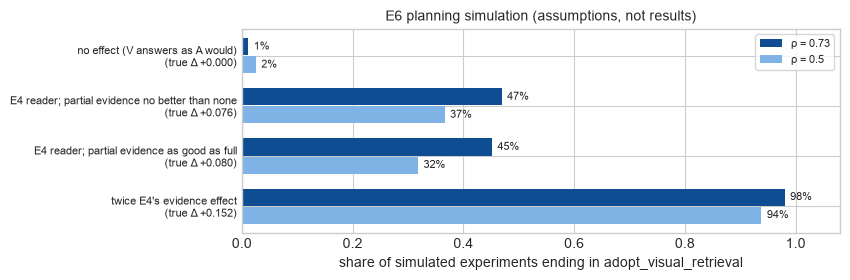

In [12]:
# Planning simulation (assumptions, not results): how often the frozen rule reaches each verdict on these 102 questions in 14 documents.
e4_app_frame = e4_table[e4_table["answerable"]]
no_evidence_strata = {"evidence_retrieved_but_dropped_by_guard", "evidence_not_retrieved"}
p_all = e4_app_frame.loc[e4_app_frame["stratum"] == "all_evidence_supplied", "correct_APP"].mean()
p_none = e4_app_frame.loc[e4_app_frame["stratum"].isin(no_evidence_strata), "correct_APP"].mean()
assert (round(p_all, 4), round(p_none, 4)) == (0.5, round(1 / 11, 4))
SIM_SCENARIOS = {  # correct-answer probability by the evidence an arm supplies
    "no effect (V answers as A would)": None,
    "E4 reader; partial evidence no better than none": {"all": p_all, "some": p_none, "none": p_none},
    "E4 reader; partial evidence as good as full": {"all": p_all, "some": p_all, "none": p_none},
    "twice E4's evidence effect": {"all": min(1.0, p_none + 2 * (p_all - p_none)), "some": p_none, "none": p_none},
}
SIM_RHOS, SIM_RUNS, SIM_BOOTSTRAP = (0.73, 0.5), 2_000, 2_000
primary_docs = held_idx.loc[ANSWERABLE, "doc_id"].to_numpy()
stratum_A = np.array([STRATUM.get((q, "A"), "none") for q in ANSWERABLE])  # mmlb-0599 (no annotated evidence): "none" in both arms
stratum_V = np.array([STRATUM.get((q, "V"), "none") for q in ANSWERABLE])


def simulate(rates, rho, rng):
    p_a = np.array([(rates or SIM_SCENARIOS["E4 reader; partial evidence no better than none"])[s] for s in stratum_A])
    p_v = p_a if rates is None else np.array([rates[s] for s in stratum_V])
    verdicts, deltas, widths = Counter(), [], []
    for _ in range(SIM_RUNS):
        u_a = rng.random(len(p_a))
        u_v = np.where(rng.random(len(p_a)) < rho, u_a, rng.random(len(p_a)))
        primary = paired_comparison((u_a < p_a).astype(float), (u_v < p_v).astype(float), primary_docs,
                                    seed=int(rng.integers(2**32)), draws=SIM_BOOTSTRAP)
        verdicts[decide(primary, {"G1": True, "G2": True})["verdict"]] += 1
        deltas.append(primary["delta"])
        widths.append(primary["ci95"][1] - primary["ci95"][0])
    return {"true delta": float((p_v - p_a).mean()), "mean simulated delta": float(np.mean(deltas)),
            **{v: verdicts[v] / SIM_RUNS for v in ("adopt_visual_retrieval", "inconclusive", "no_meaningful_difference", "visual_worse")},
            "median 95 % interval width": float(np.median(widths))}


started = time.perf_counter()
sim_rng = np.random.default_rng(SEEDS["planning_simulation"])
planning = pd.DataFrame([{"scenario": name, "rho": rho, **simulate(rates, rho, sim_rng)} for name, rates in SIM_SCENARIOS.items() for rho in SIM_RHOS])
planning.to_csv(E6_DIR / "planning_simulation.csv", index=False)
recorded = pd.DataFrame(SPEC["planning_simulation"]["values"])
assert planning.round(3).equals(recorded[planning.columns].round(3)), "the planning simulation differs from the spec"
print(f"{len(planning) * SIM_RUNS:,} simulated experiments in {time.perf_counter() - started:.0f} s "
      f"({SIM_BOOTSTRAP:,} bootstrap draws each, exact sign-flip test, guardrails assumed met). Planning values, not results:")
display(planning.round(3))

fig, ax = plt.subplots(figsize=(8.6, 2.9))
labels = [f"{s}\n(true Δ {d:+.3f})" for s, d in planning.drop_duplicates("scenario")[["scenario", "true delta"]].itertuples(index=False)]
for offset, rho, color in ((-0.18, 0.73, "#0F4D92"), (0.18, 0.5, "#7FB3E6")):
    values = planning.loc[planning["rho"] == rho, "adopt_visual_retrieval"].to_numpy()
    ax.barh(np.arange(len(labels)) + offset, values, height=0.34, color=color, label=f"ρ = {rho}")
    for y, v in zip(np.arange(len(labels)) + offset, values):
        ax.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8)
ax.set_yticks(np.arange(len(labels)), labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, 1.08)
ax.set_xlabel("share of simulated experiments ending in adopt_visual_retrieval")
ax.set_title("E6 planning simulation (assumptions, not results)", fontsize=10)
ax.legend(fontsize=8, loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

## 6. Execution: budget guard, append-only log, resume, smoke gate

The executor follows E4's design, which completed 98 paid calls without an incident.

**Engine.** Each call goes through the pre-call check above, then one SDK call, then the reader's parser. The executor fingerprints the arguments the SDK actually receives.

**Cache and log.** Each reply goes into a run-scoped cache, fsynced *before* its log record is written. Both files are append-only.

**Stop rules:**

| what happens | effect |
|---|---|
| integrity failure: the request differs from the plan, the SDK arguments differ, or another model served the call | stop in every mode; the run cannot be resumed |
| any API error other than a waitable 429 | stop |
| a quota or billing 429 | stop; never retried |
| an ordinary 429 | wait it out, without using an attempt |
| a call that could take the cumulative spend above the ceiling | stop before that call |

**Smoke and full modes.** A contract failure (unparseable or truncated reply) or a token deviation gates the smoke stage. In full mode it is only recorded and scored 0, so the population is never truncated by outcome.

**What the logs contain.** No annotation ever enters a run's logs.

The tests below drive the executor with real SDK objects carrying invented replies. They are **interface tests**: none of their replies enters any result.

In [13]:
# E6 executor: engine, list-price budget guard (cumulative, failed attempts included), run-scoped cache, durable log, resume, smoke gate.
MAX_ATTEMPTS = EXECUTION["max_attempts_per_request"]
RATE_LIMIT = EXECUTION["rate_limit"]
TOLERANCE = SPEC["token_accounting"]["tolerance_tokens"]
RESPONDED = {"ok", "parse_error"}  # a reply exists; parse_error is the model's own failure and scores 0
NOT_AN_ATTEMPT = {"budget_stop", "not_attempted", "rate_limited"}
POSSIBLY_BILLED_ERRORS = {"network", "server", "unexpected"}  # a timeout or failed response may still be billed; a 4xx is not
RESPONSE_FIELDS = ("raw_response", "finish_reason", "served_model", "system_fingerprint", "prompt_tokens", "completion_tokens", "cached_prompt_tokens")
READER_FIELDS = ("reader_answer", "reader_cited_pages", "reader_error")
CALL_FIELDS = RESPONSE_FIELDS + ("api_latency_s", "sent_fingerprint") + READER_FIELDS
QUOTA_CODES = {"insufficient_quota", "credit_balance_exhausted", "billing_hard_limit_reached", "billing_not_active"}
SECRET_PATTERN = re.compile(r"sk-[A-Za-z0-9_\-\*]{4,}")


def utc_now():
    return datetime.now(timezone.utc).isoformat(timespec="milliseconds")


def append_durable(path, payload):
    with open(path, "a") as handle:
        handle.write(json.dumps(payload, default=str) + "\n")
        handle.flush()
        os.fsync(handle.fileno())


def write_new_text(path, text):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "x") as handle:  # never overwrites
        handle.write(text)


def classify_api_error(error):
    # (category, retryable) from the exception class and the structured code, never from the free-text message.
    if isinstance(error, openai.RateLimitError):
        if getattr(error, "code", None) in QUOTA_CODES or getattr(error, "type", None) in QUOTA_CODES:
            return "quota_or_billing", False
        return "rate_limit", True
    if isinstance(error, openai.AuthenticationError):
        return "authentication", False
    if isinstance(error, openai.PermissionDeniedError):
        return "permission", False
    if isinstance(error, openai.NotFoundError):
        return "model_access", False
    if isinstance(error, (openai.BadRequestError, openai.UnprocessableEntityError)):
        return "invalid_request", False
    if isinstance(error, openai.APIConnectionError):  # includes APITimeoutError
        return "network", True
    if isinstance(error, openai.InternalServerError) or (isinstance(error, openai.APIStatusError) and error.status_code in (408, 409)):
        return "server", True
    return "unexpected", False


def describe_api_error(error):
    category, retryable = classify_api_error(error)
    return {"category": category, "retryable": retryable, "exception": type(error).__name__, "status_code": getattr(error, "status_code", None),
            "code": getattr(error, "code", None), "type": getattr(error, "type", None),
            "message": SECRET_PATTERN.sub("sk-<redacted>", str(getattr(error, "message", error)))[:300], "request_id": getattr(error, "request_id", None)}


def response_fields(response):
    usage = response.usage
    details = getattr(usage, "prompt_tokens_details", None) if usage else None
    return {"raw_response": response.choices[0].message.content or "", "finish_reason": response.choices[0].finish_reason, "served_model": response.model,
            "system_fingerprint": getattr(response, "system_fingerprint", None), "prompt_tokens": usage.prompt_tokens if usage else None,
            "completion_tokens": usage.completion_tokens if usage else None, "cached_prompt_tokens": getattr(details, "cached_tokens", None)}


class TokenPacer:
    # Keeps the expected prompt tokens sent in any 60-second window under tokens_per_minute.
    def __init__(self, tokens_per_minute, clock=time.monotonic, sleep=time.sleep):
        self.tokens_per_minute, self.clock, self.sleep, self.window = tokens_per_minute, clock, sleep, deque()

    def wait(self, tokens):
        while True:
            now = self.clock()
            while self.window and now - self.window[0][0] >= 60:
                self.window.popleft()
            if not self.window or sum(t for _, t in self.window) + tokens <= self.tokens_per_minute:
                break
            self.sleep(60 - (now - self.window[0][0]))
        self.window.append((self.clock(), tokens))


def make_engine(create):
    # One call: the pre-call check (raises before sending), the SDK call, the reader's parser and finish-reason rule.
    # create is wrapped only to record latency and the fingerprint of the arguments it actually received.
    def engine(request):
        check_request(request)
        seen = {}

        def recording_create(**kwargs):
            seen["sent_fingerprint"] = request_fingerprint(kwargs)
            started = time.perf_counter()
            seen["response"] = create(**kwargs)
            seen["api_latency_s"] = round(time.perf_counter() - started, 3)
            return seen["response"]

        fields = response_fields(recording_create(**request))
        answer, cited, problem = parse_reply(fields["raw_response"], fields["finish_reason"])
        return {**fields, "api_latency_s": seen["api_latency_s"], "sent_fingerprint": seen["sent_fingerprint"],
                "reader_answer": answer, "reader_cited_pages": cited, "reader_error": problem}

    return engine


def cache_key(run_id, replicate_id, fingerprint):
    return sha256_bytes(f"{run_id}:{replicate_id}:{fingerprint}".encode())


def load_cache(path):
    return {entry["cache_key"]: entry for entry in read_jsonl(path)} if path.is_file() else {}


def reply_cost(fields):
    # List price of a received reply on its billed tokens (cached input is billed lower: an upper bound of the true charge).
    return (fields.get("prompt_tokens") or 0) * PRICE["input"] + (fields.get("completion_tokens") or 0) * PRICE["output"]


def failed_attempt_charge(log_path):
    # Conservative: every attempt that failed after it may have been processed is charged its full upper bound.
    if not log_path.is_file():
        return 0.0
    return sum(r["cost_upper_usd"] for r in read_jsonl(log_path)
               if r["status"] == "api_error" and (r.get("error") or {}).get("category") in POSSIBLY_BILLED_ERRORS)


def run_spent_usd(cache, log_path):
    return sum(reply_cost(entry) for entry in cache.values()) + failed_attempt_charge(log_path)


def prior_spend_usd(runs_dir, spec_sha256, exclude_run_id):
    # Cumulative budget: what every other E6 run under the same spec hash received or may have been billed for.
    total = 0.0
    for settings_path in sorted(runs_dir.glob("*/settings.json")) if runs_dir.is_dir() else []:
        settings = json.loads(settings_path.read_text())
        if settings.get("spec_sha256") == spec_sha256 and settings.get("run_id") != exclude_run_id:
            total += run_spent_usd(load_cache(settings_path.parent / "response_cache.jsonl"), settings_path.parent / "execution_log.jsonl")
    return total


def latest_records(log_records):
    latest = {}
    for record in log_records:
        latest[record["execution_index"]] = record
    return [latest[index] for index in sorted(latest)]


def remaining_items(plan, log_records):
    # Items without a reply, and the attempts each has used (a 429 is not an attempt). A logged integrity failure blocks resumption.
    assert not any(r.get("integrity_valid") is False or r["status"] == "integrity_error" for r in log_records), \
        "an integrity failure is logged in this run; it cannot be resumed"
    responded = {r["execution_index"] for r in log_records if r["status"] in RESPONDED}
    attempts = Counter(r["execution_index"] for r in log_records if r["status"] not in NOT_AN_ATTEMPT)
    return [item for item in plan if item["execution_index"] not in responded], attempts


def verify_request(entry):
    # Re-derived from the bytes about to be sent: image hashes and fingerprint equal the plan.
    return [i["sha256"] for i in request_parts(entry["request"])[1]] == entry["image_sha256"] and request_fingerprint(entry["request"]) == entry["fingerprint"]


def response_checks(record):
    integrity = {"request_content_verified": bool(record.get("request_content_verified")),
                 "sent_request_equals_plan": record.get("sent_fingerprint") == record.get("fingerprint"),
                 "served_model_is_the_snapshot": record.get("served_model") == SNAPSHOT}
    contract = {"reader_parsed_the_reply": record.get("reader_error") is None, "finished_with_stop": record.get("finish_reason") == "stop"}
    diagnostics = {"prompt_tokens_within_tolerance": record.get("prompt_tokens") is not None
                   and abs(record["prompt_tokens"] - record["expected_prompt_tokens"]) <= TOLERANCE,
                   "cached_token_field_recorded": record.get("cached_prompt_tokens") is not None}
    return integrity, contract, diagnostics


def execute_plan(plan, engine, run_id, cache, cache_path, log_path, *, stop_on_gate_failure, budget_usd, attempts=None, pause_s=0.0, pacer=None, sleep=time.sleep):
    # One logged record per attempt. Before every call: spend received or possibly billed + the upper bound of this and every later call <= budget_usd.
    attempts = Counter() if attempts is None else attempts
    for position, item in enumerate(plan):
        entry = entry_of(item)
        attempts[item["execution_index"]] += 1
        if attempts[item["execution_index"]] > MAX_ATTEMPTS:
            return f"attempt limit reached at execution index {item['execution_index']}"
        key = cache_key(run_id, item["replicate_id"], entry["fingerprint"])
        record = {**item, "attempt": attempts[item["execution_index"]], "arm_label": ARMS[item["arm"]], "doc_id": entry["doc_id"],
                  "supplied_pages": entry["supplied_pages"], "requested_model": SNAPSHOT, "status": "not_attempted", "source": None, "pred": "",
                  "cited_pages": [], "raw_response": None, "image_sha256": entry["image_sha256"], "image_dimensions": entry["image_dimensions"],
                  "request_content_verified": verify_request(entry), "fingerprint": entry["fingerprint"],
                  "expected_prompt_tokens": entry["expected_prompt_tokens"], "prompt_token_bound": entry["prompt_token_bound"],
                  "cost_upper_usd": item_cost_upper(item),
                  "cache_provenance": {"namespace": f"{run_id}:{item['replicate_id']}", "cache_key": key, "hit": False, "saved_at": None},
                  "request_started_at": None, "request_completed_at": None}
        stop_reason, cached = None, cache.get(key)
        projected = run_spent_usd(cache, log_path) + sum(item_cost_upper(later) for later in plan[position:])
        if not record["request_content_verified"]:
            record["status"] = "integrity_error"
            stop_reason = f"request content differs from the plan at {item['qid']} {item['arm']}"
        elif cached is not None:  # only this run and replicate can supply it: an interrupted earlier attempt
            record.update({field: cached.get(field) for field in CALL_FIELDS}, source="cache")
            record["cache_provenance"].update(hit=True, saved_at=cached["saved_at"])
        elif projected > budget_usd:
            record["status"] = "budget_stop"
            stop_reason = f"budget: projected ${projected:.4f} exceeds the remaining ${budget_usd:.4f} before {item['qid']}"
        else:
            waits = list(RATE_LIMIT["backoff_s"])
            if pacer is not None:
                pacer.wait(entry["expected_prompt_tokens"])
            result = None
            while True:
                sleep(pause_s)
                record["request_started_at"] = utc_now()
                try:
                    result = engine(entry["request"])
                except openai.RateLimitError as error:
                    category, _ = classify_api_error(error)
                    record.update(status="rate_limited" if category == "rate_limit" else "api_error", request_completed_at=utc_now(), error=describe_api_error(error))
                    if category == "rate_limit" and waits:  # waiting can help: log it, wait, retry within the same attempt
                        append_durable(log_path, {**record, "rate_limit_wait_s": waits[0]})
                        sleep(waits.pop(0))
                        record = {k: v for k, v in record.items() if k != "error"} | {"status": "not_attempted", "request_completed_at": None}
                        continue
                    stop_reason = (f"rate_limit persisted after {len(RATE_LIMIT['backoff_s'])} waits at {item['qid']}" if category == "rate_limit"
                                   else f"{category} at {item['qid']}")
                except openai.OpenAIError as error:
                    record.update(status="api_error", request_completed_at=utc_now(), error=describe_api_error(error))
                    stop_reason = f"{record['error']['category']} at {item['qid']}"
                except ValueError as error:  # the pre-call check refused the request: nothing was sent
                    record.update(status="integrity_error", request_completed_at=utc_now(), error={"category": "pre_call_refusal", "message": str(error)})
                    stop_reason = f"pre-call check refused the request at {item['qid']}: {error}"
                break
            if result is not None:
                record["request_completed_at"] = utc_now()
                fields = {field: result.get(field) for field in CALL_FIELDS}
                payload = {"cache_key": key, "cache_namespace": record["cache_provenance"]["namespace"], "replicate_id": item["replicate_id"],
                           "execution_index": item["execution_index"], "fingerprint": entry["fingerprint"], "saved_at": utc_now(), **fields}
                append_durable(cache_path, payload)  # the reply is durable before its log record
                cache[key] = payload
                record.update(fields, source="live")
                record["cache_provenance"]["saved_at"] = payload["saved_at"]
        if record["raw_response"] is not None:
            record.update(pred=record["reader_answer"] if record["reader_error"] is None else "", cited_pages=record["reader_cited_pages"] or [],
                          parse_error=record["reader_error"], status="ok" if record["reader_error"] is None else "parse_error")
            integrity, contract, diagnostics = response_checks(record)
            record.update(prompt_token_difference=None if record.get("prompt_tokens") is None else record["prompt_tokens"] - record["expected_prompt_tokens"],
                          integrity_checks=integrity, contract_checks=contract, diagnostic_checks=diagnostics,
                          integrity_valid=all(integrity.values()), contract_valid=all(contract.values()), diagnostic_valid=all(diagnostics.values()))
            if not record["integrity_valid"]:
                stop_reason = f"integrity check failed at {item['qid']}: " + ", ".join(k for k, ok in integrity.items() if not ok)
            elif stop_on_gate_failure and not (record["contract_valid"] and record["diagnostic_valid"]):
                stop_reason = f"technical gate failed at {item['qid']}: " + ", ".join(k for k, ok in {**contract, **diagnostics}.items() if not ok)
        append_durable(log_path, record)
        if stop_reason is not None:
            return stop_reason
    return None


def smoke_gate(records):
    checks = {"one reply per arm for the smoke question": len(records) == 2 and {r["arm"] for r in records} == set(ARMS) and {r["qid"] for r in records} == {SMOKE_QID},
              "integrity: verified request, SDK arguments equal the plan, served snapshot": all(r.get("integrity_valid") for r in records),
              "contract: every reply parsed, finish 'stop'": all(r.get("contract_valid") for r in records),
              "diagnostics: prompt tokens within tolerance, cached-token field recorded": all(r.get("diagnostic_valid") for r in records)}
    return checks, all(checks.values())


def run_stages(mode, engine, run_id, run_dir, *, budget_usd, prior_spent_usd=0.0, pacer=None, sleep=time.sleep):
    # budget_usd: the cumulative ceiling for all E6 runs under this spec; prior_spent_usd: what other runs already received.
    plan = execution_plan(mode)
    cache_path, log_path = run_dir / "response_cache.jsonl", run_dir / "execution_log.jsonl"
    log_now = lambda: read_jsonl(log_path) if log_path.is_file() else []
    segments = {"smoke": [i for i in plan if i["replicate_id"] == "technical_smoke"], "main": [i for i in plan if i["replicate_id"] == "main_r1"]}

    def run_segment(name, stop_on_gate_failure):
        todo, attempts = remaining_items(segments[name], log_now())
        reserve = sum(item_cost_upper(i) for i in remaining_items(segments["main"], log_now())[0]) if name == "smoke" else 0.0
        return execute_plan(todo, engine, run_id, load_cache(cache_path), cache_path, log_path, stop_on_gate_failure=stop_on_gate_failure,
                            budget_usd=budget_usd - prior_spent_usd - reserve, attempts=attempts, pause_s=EXECUTION["pause_between_calls_s"],
                            pacer=pacer, sleep=sleep) if todo else None

    stop = run_segment("smoke", True)
    smoke_checks, smoke_ok = smoke_gate([r for r in latest_records(log_now()) if r["replicate_id"] == "technical_smoke"])
    if not (run_dir / "smoke_gate.json").exists():
        write_new_text(run_dir / "smoke_gate.json", json.dumps({"passed": smoke_ok, "checks": smoke_checks, "stop_reason": stop}, indent=2))
    if smoke_ok and mode == "full":
        stop = run_segment("main", False)
    elif not smoke_ok:
        stop = stop or "smoke gate failed"
    final = latest_records(log_now())
    replied = [r for r in final if r["status"] in RESPONDED]
    received = sum(reply_cost(e) for e in load_cache(cache_path).values())
    failed_charge = failed_attempt_charge(log_path)
    summary = {"run_id": run_id, "mode": mode, "complete": len(final) == len(plan) == len(replied) and stop is None, "stop_reason": stop,
               "smoke_gate_passed": smoke_ok, "smoke_checks": smoke_checks, "planned_calls": len(plan),
               "api_calls_sent": sum(r["source"] == "live" or r["status"] in ("api_error", "rate_limited") for r in log_now()),
               "rate_limited_responses": sum(r["status"] == "rate_limited" for r in log_now()), "replied": len(replied),
               "status_counts": dict(Counter(r["status"] for r in final)), "integrity_valid": all(r.get("integrity_valid") for r in replied),
               "contract_failures": sum(not r.get("contract_valid", False) for r in replied),
               "prompt_token_differences": dict(Counter(r.get("prompt_token_difference") for r in replied)),
               "diagnostic_flags": sum(not r.get("diagnostic_valid", False) for r in replied),
               "list_price_cost_usd": round(received, 6), "possibly_billed_failed_attempts_upper_usd": round(failed_charge, 6),
               "cumulative_list_price_cost_usd": round(prior_spent_usd + received + failed_charge, 6), "approved_cumulative_budget_usd": budget_usd,
               "completed_at": utc_now()}
    if summary["complete"]:
        for replicate_id, arm in sorted({(r["replicate_id"], r["arm"]) for r in final}):
            write_new_text(run_dir / f"predictions_{replicate_id}_{arm}.jsonl",
                           "".join(json.dumps(r, default=str) + "\n" for r in final if (r["replicate_id"], r["arm"]) == (replicate_id, arm)))
        write_new_text(run_dir / "completion.json", json.dumps(summary, indent=2, default=str))
    else:
        write_new_text(run_dir / f"stop_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}.json", json.dumps(summary, indent=2, default=str))
    return summary


def notebook_code_sha256(notebook_json):
    # Code-cell sources only, in order: executing the notebook does not change it; editing code does.
    return sha256_bytes(json.dumps(["".join(c["source"]) if isinstance(c["source"], list) else c["source"]
                                    for c in notebook_json["cells"] if c["cell_type"] == "code"]).encode())


def code_provenance():
    git = lambda *args: subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, text=True).stdout.strip()
    head = git("rev-parse", "HEAD")
    disk_code = notebook_code_sha256(json.loads((PROJECT_ROOT / NOTEBOOK_RELPATH).read_text()))
    head_notebook = git_show_bytes(head, NOTEBOOK_RELPATH)
    return {"git_commit": head, "branch": git("rev-parse", "--abbrev-ref", "HEAD"), "spec_sha256": SPEC_SHA256,
            "spec_committed": git_show_bytes(head, SPEC_RELPATH) == SPEC_BYTES == (PROJECT_ROOT / SPEC_RELPATH).read_bytes(),
            "notebook05_code_sha256": disk_code,
            "notebook05_code_committed": head_notebook is not None and notebook_code_sha256(json.loads(head_notebook)) == disk_code,
            "application_module_sha256_informative": {str(p.relative_to(PROJECT_ROOT)): sha256_bytes(p.read_bytes())
                                                       for p in sorted((PROJECT_ROOT / "src" / "visualdoc").glob("*.py"))},
            "git_status": git("status", "--porcelain").splitlines()}


DESIGN = {
    "spec_id": SPEC["spec_id"], "spec_sha256": SPEC_SHA256, "spec_status": SPEC["status"], "generated_at": utc_now(), "model": SNAPSHOT,
    "system_prompt_hash": READER["system_prompt_hash"], "qids": QIDS, "answerable": ANSWERABLE, "evidence_qids": EVIDENCE_QIDS,
    "documents": HELDOUT_DOCS, "smoke_qid": SMOKE_QID, "token_tolerance": TOLERANCE, "strata": {f"{q}|{a}": s for (q, a), s in STRATUM.items()},
    "requests": {f"{e['qid']}|{e['arm']}": {k: e[k] for k in ("fingerprint", "expected_prompt_tokens", "prompt_token_bound", "image_sha256", "supplied_pages", "top5")}
                 for e in REQUESTS.values()},
    "plans": PLANS, "decision_rule": RULE,
}
(E6_DIR / "design.json").write_text(json.dumps(DESIGN, indent=1))
print(f"Executor defined; offline design saved ({len(DESIGN['requests'])} requests, plans of {len(PLANS['smoke'])} and {len(PLANS['full'])} calls).")

Executor defined; offline design saved (236 requests, plans of 2 and 238 calls).


In [14]:
# Interface tests of the executor: real SDK ChatCompletion objects and real SDK exceptions carrying invented replies.
# None of these replies ever enters a result.
MOCK_REQUEST = httpx.Request("POST", "https://api.openai.com/v1/chat/completions")


def mock_status_error(cls, status, body):
    return cls(f"Error code: {status} - {body}", response=httpx.Response(status, request=MOCK_REQUEST, headers={"x-request-id": "req_mock"}), body=body)


quota_error = mock_status_error(openai.RateLimitError, 429, {"message": "You have no credits remaining.", "type": "insufficient_quota", "param": None,
                                                              "code": "credit_balance_exhausted"})
rate_error = mock_status_error(openai.RateLimitError, 429, {"message": "Rate limit reached for tokens", "type": "tokens", "param": None, "code": "rate_limit_exceeded"})
server_error = mock_status_error(openai.InternalServerError, 500, {"message": "The server had an error.", "type": "server_error", "param": None, "code": None})
expected_by_fingerprint = {e["fingerprint"]: e["expected_prompt_tokens"] for e in REQUESTS.values()}


def mock_completion(content, *, finish_reason, prompt_tokens, model, cached=0):
    usage = {"prompt_tokens": prompt_tokens, "completion_tokens": 10, "total_tokens": prompt_tokens + 10, "prompt_tokens_details": {"cached_tokens": cached}}
    return ChatCompletion.model_validate({"id": "chatcmpl-mock-e6", "object": "chat.completion", "created": 0, "model": model, "system_fingerprint": "fp_mock_e6",
                                          "choices": [{"index": 0, "finish_reason": finish_reason, "message": {"role": "assistant", "content": content}}], "usage": usage})


def fake_openai(replies, *, errors=None, token_shift=1, model=None):
    # Stand-in for client.chat.completions.create; prompt tokens = expectation + 1, the offset of every frozen E4 call.
    calls = []

    def create(**request):
        calls.append(request_fingerprint(request)[:12])
        if errors and len(calls) in errors:
            raise errors[len(calls)]
        raw, finish = replies[min(len(calls), len(replies)) - 1]
        return mock_completion(raw, finish_reason=finish, prompt_tokens=expected_by_fingerprint.get(request_fingerprint(request), 0) + token_shift,
                               model=model or SNAPSHOT)

    return create, calls


OK, TRUNCATED = ('{"answer": 63, "cited_pages": [6]}', "stop"), ('{"answer": "Europe IPO", "cited_pa', "length")
TEST_BUDGET = 50.0
no_sleep = lambda _: None

# A. Plans: composition, adjacent counterbalanced pairs, every question once per arm, the smoke pair first.
smoke_plan, full_plan = PLANS["smoke"], PLANS["full"]
main_items = [i for i in full_plan if i["replicate_id"] == "main_r1"]
assert [i["execution_index"] for i in full_plan] == list(range(1, 239)) and [(i["qid"], i["arm"]) for i in full_plan[:2]] == [(i["qid"], i["arm"]) for i in smoke_plan]
assert {i["arm"] for i in smoke_plan} == set(ARMS) and len({(i["replicate_id"], i["qid"], i["arm"]) for i in full_plan}) == 238
assert all(sorted(i["qid"] for i in main_items if i["arm"] == arm) == QIDS for arm in ARMS)
pairs = {}
for item in main_items:
    pairs.setdefault(item["pair_index"], []).append(item)
assert all(len(g) == 2 and g[0]["qid"] == g[1]["qid"] and g[1]["execution_index"] == g[0]["execution_index"] + 1 for g in pairs.values())
opens = Counter(g[0]["arm"] for g in pairs.values())
assert opens == Counter({"A": 59, "V": 59}) and [g[0]["qid"] for g in pairs.values()] != QIDS
composition = EXECUTION["plan_composition"]["full"]
assert (composition["calls"], composition["main_r1_A"], composition["main_r1_V"], composition["pairs"]) == (len(full_plan), 118, 118, len(pairs))
provenance_now = code_provenance()
assert {"spec_committed", "notebook05_code_committed", "git_commit"} <= set(provenance_now)

mini = [dict(i) for i in smoke_plan] + [dict(i) for i in pairs[1]] + [dict(i) for i in pairs[2]]
for index, item in enumerate(mini, start=1):
    item["execution_index"] = index
run = lambda plan, create, name, folder, **kw: execute_plan(plan, make_engine(create), name, kw.pop("cache", {}), folder / f"{name}_cache.jsonl",
                                                            folder / f"{name}_log.jsonl", **{"stop_on_gate_failure": True, "budget_usd": TEST_BUDGET, **kw})

with tempfile.TemporaryDirectory() as folder:
    folder = Path(folder)
    # B. A complete mini run: every reply live and parsed, SDK arguments equal to the plan, nothing Base64 and no annotation saved.
    create, calls = fake_openai([OK])
    assert run(mini, create, "b", folder) is None
    log = read_jsonl(folder / "b_log.jsonl")
    assert len(calls) == 6 and all(r["source"] == "live" and r["integrity_valid"] and r["contract_valid"] and r["diagnostic_valid"] for r in log)
    assert all(r["pred"] == 63 and r["cited_pages"] == [6] and r["reader_error"] is None and r["sent_fingerprint"] == r["fingerprint"] for r in log)
    saved = (folder / "b_cache.jsonl").read_text() + (folder / "b_log.jsonl").read_text()
    assert all(r["prompt_token_difference"] == 1 for r in log) and "base64," not in saved
    assert not any(field in saved for field in ('"evidence_pages"', '"answer_format"', '"answerable"', '"stratum"'))

    # C. Credits exhausted: one call, no wait, stopped, not charged. D. Ordinary rate limits: waited out within the same attempt.
    create, calls = fake_openai([OK], errors={1: quota_error})
    waited = []
    assert run(mini, create, "c", folder, sleep=waited.append).startswith("quota_or_billing") and len(calls) == 1 and waited == [0.0]
    assert failed_attempt_charge(folder / "c_log.jsonl") == 0.0
    waited = []
    create, calls = fake_openai([OK], errors={1: rate_error, 2: rate_error})
    assert run(mini[:2], create, "d", folder, pause_s=1.0, sleep=waited.append) is None
    assert [r["status"] for r in read_jsonl(folder / "d_log.jsonl")] == ["rate_limited", "rate_limited", "ok", "ok"]
    assert waited == [1.0, RATE_LIMIT["backoff_s"][0], 1.0, RATE_LIMIT["backoff_s"][1], 1.0, 1.0]
    create, calls = fake_openai([OK], errors={n: rate_error for n in range(1, 50)})
    assert run(mini[:1], create, "d2", folder, sleep=no_sleep).startswith("rate_limit persisted")
    assert remaining_items(mini[:1], read_jsonl(folder / "d2_log.jsonl"))[1][1] == 0  # a 429 is not an attempt

    # E. Server error on the 3rd call (charged its upper bound); resume sends only what is missing; a 2nd failure exhausts the attempts.
    create, calls = fake_openai([OK], errors={3: server_error})
    assert run(mini, create, "e", folder).startswith("server")
    assert np.isclose(failed_attempt_charge(folder / "e_log.jsonl"), item_cost_upper(mini[2]))
    todo, attempts = remaining_items(mini, read_jsonl(folder / "e_log.jsonl"))
    create, calls = fake_openai([OK])
    assert [i["execution_index"] for i in todo] == [3, 4, 5, 6] and run(todo, create, "e", folder, cache=load_cache(folder / "e_cache.jsonl"), attempts=attempts) is None
    assert len(calls) == 4 and [r["attempt"] for r in latest_records(read_jsonl(folder / "e_log.jsonl"))] == [1, 1, 2, 1, 1, 1]
    run(mini[:1], fake_openai([OK], errors={1: server_error})[0], "e2", folder)
    todo, attempts = remaining_items(mini[:1], read_jsonl(folder / "e2_log.jsonl"))
    run(todo, fake_openai([OK], errors={1: server_error})[0], "e2", folder, attempts=attempts)
    todo, attempts = remaining_items(mini[:1], read_jsonl(folder / "e2_log.jsonl"))
    assert run(todo, fake_openai([OK])[0], "e2", folder, attempts=attempts).startswith("attempt limit")

    # F. Crash after the reply was cached but before it was logged: resume reuses the cached reply without a call.
    run(mini[:2], fake_openai([OK])[0], "f", folder)
    (folder / "f_log.jsonl").write_text((folder / "f_log.jsonl").read_text().splitlines(keepends=True)[0])
    todo, attempts = remaining_items(mini[:2], read_jsonl(folder / "f_log.jsonl"))
    create, calls = fake_openai([OK])
    run(todo, create, "f", folder, cache=load_cache(folder / "f_cache.jsonl"), attempts=attempts)
    recovered = read_jsonl(folder / "f_log.jsonl")[-1]
    assert not calls and recovered["source"] == "cache" and recovered["cache_provenance"]["hit"] and recovered["pred"] == 63

    # G. Integrity stops every mode and blocks resumption: another served model; SDK arguments that differ from the plan;
    #    a request whose image no longer matches the plan (never sent).
    create, calls = fake_openai([OK], model="gpt-4o-mini-2099-01-01")
    stop = run(mini, create, "g1", folder, stop_on_gate_failure=False)
    assert stop.startswith("integrity") and "served_model_is_the_snapshot" in stop and len(calls) == 1

    def altered(request):  # a change between the executor and the SDK: one space added to the question header
        changed = json.loads(json.dumps(request))
        changed["messages"][1]["content"][0]["text"] += " "
        return changed

    g2_engine = make_engine(fake_openai([OK])[0])
    stop = execute_plan(mini[:1], lambda request: g2_engine(altered(request)), "g2", {}, folder / "g2_cache.jsonl", folder / "g2_log.jsonl",
                        stop_on_gate_failure=False, budget_usd=TEST_BUDGET)
    assert stop.startswith("integrity") and "sent_request_equals_plan" in stop
    for name in ("g1", "g2"):
        try:
            remaining_items(mini, read_jsonl(folder / f"{name}_log.jsonl"))
            raise RuntimeError("an integrity failure was resumable")
        except AssertionError as error:
            assert "cannot be resumed" in str(error)
    key = (mini[2]["qid"], mini[2]["arm"])
    original = REQUESTS[key]
    tampered = json.loads(json.dumps(original["request"]))
    image_index = next(i for i, part in enumerate(tampered["messages"][1]["content"]) if part["type"] == "image_url")
    other_page = next(p for p in range(1, PAGE_COUNT[original["doc_id"]] + 1) if p not in original["supplied_pages"])
    tampered["messages"][1]["content"][image_index]["image_url"]["url"] = "data:image/png;base64," + base64.b64encode(
        manifest_png(held_manifest, original["doc_id"], other_page)).decode("ascii")
    try:
        REQUESTS[key] = {**original, "request": tampered}
        create, calls = fake_openai([OK])
        assert run(mini[2:3], create, "g3", folder).startswith("request content differs") and not calls
    finally:
        REQUESTS[key] = original
    assert verify_request(REQUESTS[key])

    # H. The pre-call check: a request whose output allowance pushes it past the context is never sent, and blocks resumption.
    big = REQUESTS[(SMOKE_QID, "A")]
    oversized = {**big["request"], "max_completion_tokens": 20_000}
    try:
        REQUESTS[("refusal-test", "A")] = {**big, "qid": "refusal-test", "request": oversized, "fingerprint": request_fingerprint(oversized)}
        create, calls = fake_openai([OK])
        stop = run([{**mini[0], "qid": "refusal-test", "arm": "A"}], create, "h", folder)
        assert stop.startswith("pre-call check refused") and "context" in stop and not calls
        assert read_jsonl(folder / "h_log.jsonl")[0]["status"] == "integrity_error"
    finally:
        del REQUESTS[("refusal-test", "A")]

    # I. A truncated reply is a contract failure; J. a missing page in the billed prompt is a token deviation.
    #    Both stop the smoke stage, and are only recorded (scored 0, flagged) in full mode.
    for name, kwargs, failed in (("i", {}, "reader_parsed_the_reply"), ("j", {"token_shift": 1 + 2 * TOLERANCE}, "prompt_tokens_within_tolerance")):
        replies = [OK, TRUNCATED, OK] if name == "i" else [OK]
        create, calls = fake_openai(replies, **kwargs)
        stop = run(mini, create, f"{name}_smoke", folder)
        assert stop.startswith("technical gate") and failed in stop
        create, calls = fake_openai(replies, **kwargs)
        assert run(mini, create, f"{name}_full", folder, stop_on_gate_failure=False) is None and len(calls) == 6
        flagged = read_jsonl(folder / f"{name}_full_log.jsonl")
        assert all(r["integrity_valid"] for r in flagged) and any(not {**r["contract_checks"], **r["diagnostic_checks"]}[failed] for r in flagged)
    i_log = read_jsonl(folder / "i_full_log.jsonl")
    assert i_log[1]["status"] == "parse_error" and i_log[1]["pred"] == "" and i_log[1]["finish_reason"] == "length"

    # K. Spending: a budget below the remaining upper bound stops before the call; earlier runs under the same spec count,
    #    including a failed attempt that may have been billed; runs under another spec do not.
    tight = sum(item_cost_upper(i) for i in mini[:2])
    create, calls = fake_openai([OK])
    assert run(mini[:2], create, "k", folder, budget_usd=tight - 1e-6).startswith("budget") and not calls
    assert run(mini[:2], create, "k2", folder, budget_usd=tight + 1e-9) is None and len(calls) == 2
    runs_dir = folder / "runs_e6"
    for run_name, spec_sha in (("old_smoke", SPEC_SHA256), ("other_spec", "f" * 64)):
        (runs_dir / run_name).mkdir(parents=True)
        (runs_dir / run_name / "settings.json").write_text(json.dumps({"run_id": run_name, "spec_sha256": spec_sha}))
        append_durable(runs_dir / run_name / "response_cache.jsonl", {"cache_key": run_name, "prompt_tokens": 100_000, "completion_tokens": 20})
        append_durable(runs_dir / run_name / "execution_log.jsonl", {"status": "api_error", "error": {"category": "network"}, "cost_upper_usd": 0.01})
    prior = prior_spend_usd(runs_dir, SPEC_SHA256, exclude_run_id="new")
    assert np.isclose(prior, 100_000 * PRICE["input"] + 20 * PRICE["output"] + 0.01)
    stage_dir = folder / "stage_budget"
    stage_dir.mkdir()
    create, calls = fake_openai([OK])
    summary = run_stages("smoke", make_engine(create), "stage_budget", stage_dir, budget_usd=prior + sum(item_cost_upper(i) for i in smoke_plan) - 1e-4,
                         prior_spent_usd=prior, sleep=no_sleep)
    assert summary["stop_reason"].startswith("budget") and not calls and not summary["complete"] and list(stage_dir.glob("stop_*.json"))

    # L. Whole stages: smoke, and a complete 238-call full run; outputs are never overwritten; the smoke stage of a full run
    #    reserves the main stage's bound, so a ceiling below the full bound stops before the first call.
    for mode in ("smoke", "full"):
        run_dir = folder / f"stage_{mode}"
        run_dir.mkdir()
        create, calls = fake_openai([OK])
        summary = run_stages(mode, make_engine(create), f"stage_{mode}", run_dir, budget_usd=TEST_BUDGET, sleep=no_sleep)
        assert summary["complete"] and summary["smoke_gate_passed"] and len(calls) == summary["replied"] == len(PLANS[mode]), summary["stop_reason"]
        assert summary["prompt_token_differences"] == {1: len(calls)} and (run_dir / "completion.json").exists()
        assert sorted(p.name for p in run_dir.glob("predictions_*.jsonl")) == sorted({f"predictions_{i['replicate_id']}_{i['arm']}.jsonl" for i in PLANS[mode]})
        try:
            run_stages(mode, make_engine(fake_openai([OK])[0]), f"stage_{mode}", run_dir, budget_usd=TEST_BUDGET, sleep=no_sleep)
            raise RuntimeError("an existing output was overwritten")
        except FileExistsError:
            pass
    run_dir = folder / "stage_reserve"
    run_dir.mkdir()
    create, calls = fake_openai([OK])
    summary = run_stages("full", make_engine(create), "stage_reserve", run_dir, budget_usd=UPPER["full"] - 0.01, sleep=no_sleep)
    assert summary["stop_reason"].startswith("budget") and not calls

# M. The token pacer waits when the next request would exceed the per-minute budget (simulated clock).
clock = {"t": 0.0}
pacer_waits = []
pacer = TokenPacer(150_000, clock=lambda: clock["t"], sleep=lambda s: (pacer_waits.append(round(s, 3)), clock.__setitem__("t", clock["t"] + s)))
for _ in range(3):
    pacer.wait(104_000)
assert pacer_waits == [60.0, 60.0]
print("Executor tests passed: plan composition and counterbalancing (59/59); a complete run with SDK arguments equal to the plan and no "
      "Base64 or annotation saved; quota 429 never retried; rate-limit 429 waited out without using an attempt; server error charged, resumed, "
      "2-attempt limit; cached-but-unlogged recovery; integrity stops that block resumption (served model, SDK arguments, swapped image never "
      "sent); the pre-call check refusing before any call; contract and token gates in smoke, flags in full; per-run, cumulative and reserved "
      "budget stops; smoke and full stages end to end without overwriting; the token pacer.")

Executor tests passed: plan composition and counterbalancing (59/59); a complete run with SDK arguments equal to the plan and no Base64 or annotation saved; quota 429 never retried; rate-limit 429 waited out without using an attempt; server error charged, resumed, 2-attempt limit; cached-but-unlogged recovery; integrity stops that block resumption (served model, SDK arguments, swapped image never sent); the pre-call check refusing before any call; contract and token gates in smoke, flags in full; per-run, cumulative and reserved budget stops; smoke and full stages end to end without overwriting; the token pacer.


In [15]:
# E6 execution. Offline (default): no client is created and nothing is sent. Paid modes: the readiness gate, then one immutable run
# directory per invocation (or the exact continuation of an interrupted one): smoke -> (full) main pairs.
e6_run_dir = None
provenance = code_provenance()
if E6_MODE == "offline":
    print("E6 offline mode: inputs, rankings, reader, requests, strata, plan, costs and the analysis verified; executor tested with mocked "
          "replies. No OpenAI client was created and nothing was sent.")
    print(f"Spec status {SPEC['status']!r}; approved budget {BUDGET['approved_ceiling_usd']} (proposed {BUDGET['proposed_ceiling_usd']}). "
          f"Planned calls: smoke {len(PLANS['smoke'])}, full {len(PLANS['full'])}.")
    print(f"Code provenance (a gate only in paid modes): HEAD {provenance['git_commit'][:12]} on {provenance['branch']}; spec committed: "
          f"{provenance['spec_committed']}; notebook-05 code committed: {provenance['notebook05_code_committed']}.")
else:
    plan = PLANS[E6_MODE]
    budget = BUDGET["approved_ceiling_usd"]
    budget_ok = isinstance(budget, (int, float)) and not isinstance(budget, bool)
    planned_upper = float(UPPER[E6_MODE])
    resume_value = os.getenv("VISUALDOC_E6_RESUME_DIR", "").strip()
    resume_dir = (Path(resume_value) if Path(resume_value).is_absolute() else PROJECT_ROOT / resume_value) if resume_value else None
    resumed_id = json.loads((resume_dir / "settings.json").read_text())["run_id"] if resume_dir else None
    prior_spent = prior_spend_usd(RUNS_DIR, SPEC_SHA256, exclude_run_id=resumed_id)
    readiness = {
        "spec frozen before live execution (status and frozen_at)": SPEC_FROZEN,
        "budget approved in the spec": budget_ok,
        f"planned upper bound ${planned_upper:.4f} within the remaining cumulative budget (already spent ${prior_spent:.4f})":
            budget_ok and prior_spent + planned_upper <= budget,
        "OPENAI_API_KEY present (value never printed)": bool(os.getenv("OPENAI_API_KEY")),
        "spec and notebook-05 code committed (equal to git HEAD)": provenance["spec_committed"] and provenance["notebook05_code_committed"],
        "before the snapshot's shutdown date (2027-01-14)": datetime.now(timezone.utc).date() < datetime(2027, 1, 14).date(),
    }
    display(pd.Series(readiness, name="ready").to_frame())
    if not all(readiness.values()):
        print("E6 live gate closed: no request was sent. Fix the failed readiness check and rerun.")
    else:
        from openai import OpenAI

        client = OpenAI(max_retries=0, timeout=EXECUTION["timeout_s"])  # the SDK's silent retries are off
        if resume_dir:
            e6_run_dir = resume_dir
            settings_record = json.loads((e6_run_dir / "settings.json").read_text())
            assert settings_record["mode"] == E6_MODE and settings_record["spec_sha256"] == SPEC_SHA256
            assert json.loads((e6_run_dir / "execution_plan.json").read_text()) == plan, "plan differs from the interrupted run"
            assert not (e6_run_dir / "completion.json").exists(), "this run is already complete"
            run_id = settings_record["run_id"]
        else:
            run_id = f"{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}_{uuid.uuid4().hex[:8]}_{E6_MODE}"
            e6_run_dir = RUNS_DIR / run_id
            e6_run_dir.mkdir(parents=True, exist_ok=False)
            settings_record = {**{k: v for k, v in DESIGN.items() if k not in ("requests", "strata", "answerable", "evidence_qids")},
                               "run_id": run_id, "mode": E6_MODE, "system_prompt": IMAGE_SYSTEM_PROMPT, "planned_calls": len(plan),
                               "max_attempts_per_request": MAX_ATTEMPTS, "approved_budget_usd": budget, "budget_scope": BUDGET["scope"],
                               "prior_spent_usd_at_creation": prior_spent, "planned_cost_upper_usd": planned_upper,
                               "cache_policy": EXECUTION["cache_policy"], "code_provenance": provenance}
            write_new_text(e6_run_dir / "settings.json", json.dumps(settings_record, indent=2))
            write_new_text(e6_run_dir / "spec_snapshot.json", SPEC_BYTES.decode())
            write_new_text(e6_run_dir / "execution_plan.json", json.dumps(plan, indent=2))
            write_new_text(e6_run_dir / "request_plan.csv", request_plan.to_csv(index=False))
        assert not e6_run_dir.resolve().is_relative_to((PROJECT_ROOT / "experiments" / "frozen").resolve()), "experiments/frozen/ is never written to"
        write_new_text(e6_run_dir / f"session_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}.json",
                       json.dumps({"started_at": utc_now(), "openai": openai.__version__, "code_provenance": provenance}, indent=2, default=str))
        summary = run_stages(E6_MODE, make_engine(client.chat.completions.create), run_id, e6_run_dir, budget_usd=budget,
                             prior_spent_usd=prior_spent, pacer=TokenPacer(EXECUTION["pacer_tokens_per_minute"]))
        display(pd.Series({k: v for k, v in summary.items() if k != "smoke_checks"}, name="E6 run").to_frame())
        display(pd.Series(summary["smoke_checks"], name="smoke gate (technical only)").to_frame())
        print("E6 run saved without overwriting any earlier output:", e6_run_dir.relative_to(PROJECT_ROOT))

E6 offline mode: inputs, rankings, reader, requests, strata, plan, costs and the analysis verified; executor tested with mocked replies. No OpenAI client was created and nothing was sent.
Spec status 'frozen-before-live-execution'; approved budget 5.6 (proposed 5.6). Planned calls: smoke 2, full 238.
Code provenance (a gate only in paid modes): HEAD 9b2438116cc6 on refactor/simplify-structure; spec committed: True; notebook-05 code committed: False.


## 7. Evaluation: written and checked before any E6 reply exists

This section turns a saved run into the pre-registered results. It is checked on real frozen data rather than on invented replies:

- **The scorer** must reproduce the 17 hand-traced cases of notebook 03 and every frozen E4 score.
- **The per-question metrics and the paired comparison** must reproduce E4's frozen counts.
- **The run validator** is exercised on synthetic run directories, which act as interface tests and are discarded.

By default, the last cell evaluates the frozen full run in `experiments/frozen/e6/`:

- it verifies the frozen files against `SHA256SUMS`;
- it validates the run (16 checks);
- it re-derives the frozen summary and per-question table byte for byte;
- it asserts the E6 regression references: A 25/102, V 38/102, 13 fixed / 0 broken, one-sided p 2⁻¹⁰, `adopt_visual_retrieval`, USD 3.721277.

`VISUALDOC_E6_RUN_DIR` evaluates another saved run instead.

In [16]:
# The frozen MMLongBench-Doc scorer (notebook 03 section 1), written out; validated on its hand-traced cases and on E4's frozen scores.
def levenshtein_distance(s1, s2):
    if len(s1) > len(s2):
        s1, s2 = s2, s1
    distances = range(len(s1) + 1)
    for i2, c2 in enumerate(s2):
        new_distances = [i2 + 1]
        for i1, c1 in enumerate(s1):
            new_distances.append(distances[i1] if c1 == c2 else 1 + min(distances[i1], distances[i1 + 1], new_distances[-1]))
        distances = new_distances
    return distances[-1]


def anls_compute(groundtruth, prediction, threshold=0.5):
    length = max(len(groundtruth.upper()), len(prediction.upper()))
    anls = 1.0 - (0.0 if length == 0 else levenshtein_distance(groundtruth, prediction) / length)
    return 0.0 if anls <= threshold else anls


def is_float_equal(reference, prediction, include_percentage=False, is_close=False):
    def get_precision(value):
        text = str(value)
        return len(text.split(".")[-1]) if "." in text else 3

    reference = float(str(reference).strip().rstrip("%").strip())
    try:
        prediction = float(str(prediction).strip().rstrip("%").strip())
    except (TypeError, ValueError):
        return False
    for item in ([reference / 100, reference, reference * 100] if include_percentage else [reference]):
        if is_close and isclose(item, prediction, rel_tol=0.01):
            return True
        precision = max(min(get_precision(prediction), get_precision(item)), 2)
        if round(prediction, precision) == round(item, precision):
            return True
    return False


def get_clean_string(s):
    s = str(s).lower().strip()
    s = re.sub(r"\s*\([^)]*\)", "", s).strip()  # official quirk kept: unit suffixes such as "miles" are not stripped
    s = re.sub(r"^['\"]|['\"]$", "", s).strip()
    s = s.strip().lstrip("$").strip()
    return s.strip().rstrip("%").strip()


EXACT_MATCH_PATTERNS = [r"\b\d+(-\d+|\s\d+)?\b", r"\b\d{4}[-\s]\d{2}[-\s]\d{2}\b", r"\b\d{4}[-\s]\d{2}\b", r"[a-zA-Z0-9._%+-]+@[a-zA-Z0-9.-]+\.[a-zA-Z]{2,}"]


def is_exact_match(s):
    return ("https://" in s or s.endswith(".py") or s.endswith("ipynb") or s.startswith("page") or "a.m." in s or "p.m." in s
            or any(re.fullmatch(pattern, s) for pattern in EXACT_MATCH_PATTERNS))


def isfloat(value):
    try:
        float(value)
        return True
    except (TypeError, ValueError):
        return False


def as_list(value):
    if isinstance(value, str) and value.startswith("["):
        try:
            value = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            pass
    return value if isinstance(value, list) else [value]


def eval_score(gt, pred, answer_type):
    if answer_type == "Int":
        try:
            gt, pred = int(gt), int(float(pred))
        except Exception:
            pred = ""
        score = gt == pred
    elif answer_type == "Float":
        try:
            gt, pred = float(get_clean_string(str(gt))), float(get_clean_string(str(pred)))
        except Exception:
            pred = ""
        score = is_float_equal(gt, pred, include_percentage=True, is_close=True)
    elif answer_type in ("Str", "None"):
        gt, pred = get_clean_string(gt), get_clean_string(pred)
        score = gt == pred if is_exact_match(gt) else anls_compute(gt, pred)
    else:  # List
        gt, pred = as_list(gt), as_list(pred)
        if len(gt) != len(pred):
            score = 0.0
        else:
            gt, pred = sorted(get_clean_string(i) for i in gt), sorted(get_clean_string(i) for i in pred)
            score = "-".join(gt) == "-".join(pred) if isfloat(gt[0]) or is_exact_match(gt[0]) else min(anls_compute(g, p) for g, p in zip(gt, pred))
    return float(score)


def accuracy_and_f1(scored):
    accuracy = scored["score"].mean()
    answerable, predicted_answer = scored["answer"] != NOT_ANSWERABLE, scored["pred"] != NOT_ANSWERABLE
    if answerable.sum() == 0 or predicted_answer.sum() == 0:
        return accuracy, 0.0
    recall = scored.loc[answerable, "score"].sum() / answerable.sum()
    precision = scored.loc[answerable, "score"].sum() / predicted_answer.sum()
    return accuracy, (2 * recall * precision / (recall + precision) if recall + precision > 0 else 0.0)


SCORING_CASES = [  # reference, prediction, format, expected (traced by hand from the official source, notebook 03)
    ("Less well-off", "less well off", "Str", 1 - 1 / 13), ("Pew Research Center", "Pew Research Centre", "Str", 1 - 2 / 19),
    ("Latinos", "Asian Americans", "Str", 0.0), ("Not answerable", "Not answerable", "None", 1.0), ("Not answerable", "The report does not say", "None", 0.0),
    ("12", "12.0", "Int", 1.0), ("12", "twelve", "Int", 0.0), ("18.29%", "18.3", "Float", 1.0), ("0.1", "10%", "Float", 1.0), ("51%", "49", "Float", 0.0),
    ("['Circle', 'Rectangle']", "['rectangle', 'circle']", "List", 1.0), ("['White', '10%']", "['White']", "List", 0.0),
    ("['2014', '2016']", "['2016', '2014']", "List", 1.0), ("https://www.example.com", "www.example.com", "Str", 0.0), ("2016-06", "2016-06", "Str", 1.0),
    ("$1,200 (approx.)", "1,200", "Str", 1.0), ("5 miles", "5", "Str", 0.0)]
assert all(isclose(eval_score(r, p, f), e, abs_tol=1e-9) for r, p, f, e in SCORING_CASES) and len(SCORING_CASES) == 17
toy = pd.DataFrame({"answer": ["A", "B", NOT_ANSWERABLE], "pred": ["A", NOT_ANSWERABLE, "C"], "score": [1.0, 0.0, 0.0]})
assert all(isclose(x, y) for x, y in zip(accuracy_and_f1(toy), (1 / 3, 0.5)))

# Every frozen E4 reply re-scored: the frozen per-question scores of notebook 03 section 17.
dev_reference = questions.set_index("qid")
rescored = Counter()
for record in e4_log:
    if record["replicate_id"] != "main_r1":
        continue
    arm = record["arm"]
    frozen_score = e4_table.loc[record["qid"], f"score_{arm}"]
    rescored[arm] += isclose(eval_score(dev_reference.loc[record["qid"], "answer"], record["pred"], dev_reference.loc[record["qid"], "answer_format"]),
                             frozen_score, abs_tol=1e-12)
assert rescored == Counter({"APP": 57, "ORACLE": 37}), rescored

# Held-out references that cannot score 1.0 against themselves (sensitivity set S1, fixed before any reply).
S1_QIDS = sorted(q for q in ANSWERABLE if eval_score(held_idx.loc[q, "answer"], held_idx.loc[q, "answer"], held_idx.loc[q, "answer_format"]) < 1)
assert S1_QIDS == SPEC["metrics"]["sensitivity"]["S1_qids"], S1_QIDS
print(f"Scorer: {len(SCORING_CASES)} hand-traced cases and the F1 check pass; the frozen E4 scores are reproduced for {rescored['APP']}/57 APP and "
      f"{rescored['ORACLE']}/37 ORACLE replies. Held-out answerable references that cannot score 1.0 against themselves (S1): {S1_QIDS}.")

Scorer: 17 hand-traced cases and the F1 check pass; the frozen E4 scores are reproduced for 57/57 APP and 37/37 ORACLE replies. Held-out answerable references that cannot score 1.0 against themselves (S1): [].


In [17]:
# From saved replies to the pre-registered results: per-question metrics, the primary comparison, guardrails, the verdict,
# secondary metrics, sensitivity analyses and the strata decomposition. Checked on the frozen E4 run below.
TEN_K_FILINGS = ["AMAZON_2017_10K.pdf", "COSTCO_2021_10K.pdf"]


def score_records(records, reference, evidence_qids):
    # One row per reply. reference: the question table indexed by qid; evidence_qids: questions whose evidence pages are usable.
    rows = []
    for r in records:
        ref = reference.loc[r["qid"]]
        responded = r["status"] in RESPONDED
        score = eval_score(ref["answer"], r["pred"], ref["answer_format"]) if responded else 0.0
        has_evidence = r["qid"] in evidence_qids
        check = citation_check(r["pred"], r["cited_pages"], r["supplied_pages"], ref["evidence_pages"] if has_evidence else None)
        rows.append({"qid": r["qid"], "doc_id": ref["doc_id"], "answerable": bool(ref["answerable"]), "answer": ref["answer"], "status": r["status"],
                     "pred": r["pred"], "score": score, "correct": score > 0, "strict": score >= 1, "abstained": check["abstained"],
                     "citation_valid": check["valid"], "citation_ok": check["valid"] and not check["missing"], "off_by_one": check["off_by_one"],
                     "missing_citation": check["missing"], "cites_evidence": check["cites_evidence"],
                     "evidence_supplied": bool(set(ref["evidence_pages"]) & set(r["supplied_pages"])) if has_evidence else None,
                     "grounded": (not check["abstained"] and check["valid"] and bool(r["cited_pages"]) and bool(check["cites_evidence"])) if has_evidence else None,
                     "supplied_pages": r["supplied_pages"], "prompt_tokens": r.get("prompt_tokens"), "completion_tokens": r.get("completion_tokens"),
                     "cached_prompt_tokens": r.get("cached_prompt_tokens"), "cost_usd": reply_cost(r), "api_latency_s": r.get("api_latency_s")})
    return pd.DataFrame(rows).set_index("qid")


def count(frame, column, mask=None):
    values = frame[column] if mask is None else frame.loc[mask, column]
    return f"{int(values.astype(bool).sum())} / {len(values)}"


def jsonable(value):
    if isinstance(value, dict):
        return {str(k): jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [jsonable(v) for v in value]
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    return value


def evaluate_e6(records_A, records_V):
    scored = {arm: score_records(records, held_idx, set(EVIDENCE_QIDS)) for arm, records in (("A", records_A), ("V", records_V))}
    for arm, frame in scored.items():
        assert sorted(frame.index) == QIDS, f"arm {arm}: a reply is missing or repeated; only complete runs are evaluated"
        assert all(frame.loc[q, "supplied_pages"] == REQUESTS[(q, arm)]["supplied_pages"] for q in QIDS)
    A, V = scored["A"].loc[QIDS], scored["V"].loc[QIDS]
    docs = held_idx.loc[QIDS, "doc_id"].to_numpy()
    answerable = held_idx.loc[QIDS, "answerable"].to_numpy(bool)
    evidence = np.isin(QIDS, EVIDENCE_QIDS)

    def compare(column, mask):
        return paired_comparison(A[column].to_numpy()[mask].astype(float), V[column].to_numpy()[mask].astype(float), docs[mask])

    primary = compare("correct", answerable)
    unanswerable = ~answerable
    guardrails = {"G1 correct abstentions on the unanswerable: V >= A - 2": int(V.loc[unanswerable, "correct"].sum()) >= int(A.loc[unanswerable, "correct"].sum()) - 2,
                  "G2 citation validity: V - A >= -0.05": float(V["citation_ok"].mean() - A["citation_ok"].mean()) >= -0.05}
    decision = decide(primary, guardrails)

    no_evidence = {arm: answerable & evidence & ~frame["evidence_supplied"].map(bool).to_numpy(bool) for arm, frame in (("A", A), ("V", V))}
    with_evidence = {arm: answerable & evidence & frame["evidence_supplied"].map(bool).to_numpy(bool) for arm, frame in (("A", A), ("V", V))}
    secondary = {
        "citations": {arm: {"valid and present (all 118)": count(f, "citation_ok"), "all cited pages supplied (all 118)": count(f, "citation_valid"),
                            "invalid citations that are off by one": f"{int(f['off_by_one'].sum())} / {int((~f['citation_valid']).sum())}",
                            "answer without a citation (all 118)": count(f, "missing_citation"),
                            "grounded: an answer citing an evidence page (101)": count(f, "grounded", evidence),
                            "correct and grounded (101)": f"{int((f['correct'] & f['grounded'].map(bool)).to_numpy()[evidence].sum())} / {int(evidence.sum())}"}
                      for arm, f in (("A", A), ("V", V))},
        "abstention": {arm: {"correct abstention (16 unanswerable)": count(f, "correct", unanswerable),
                             "unanswerable answered with content": count(f.assign(answered=~f["abstained"]), "answered", unanswerable),
                             "false abstention with evidence supplied (answerable)": count(f, "abstained", with_evidence[arm]),
                             "grounded abstention: no evidence supplied (answerable)": count(f, "abstained", no_evidence[arm]),
                             "unsupported answer: no evidence supplied (answerable)": count(f.assign(answered=~f["abstained"]), "answered", no_evidence[arm])}
                       for arm, f in (("A", A), ("V", V))},
        "latency": {"A": {"API latency s, median / 90th percentile": f"{A['api_latency_s'].median():.2f} / {A['api_latency_s'].quantile(0.9):.2f}",
                          "retrieval per question (E5, development machine)": f"BM25 query {E5_COST['BM25: index, ms per page / query, ms'].split('/')[1].strip()} ms",
                          "indexing per page (E5)": f"BM25 {E5_COST['BM25: index, ms per page / query, ms'].split('/')[0].strip()} ms + text extraction "
                                                    f"{E5_COST['baseline text: held-out extraction incl. OCR, s per page']}"},
                    "V": {"API latency s, median / 90th percentile": f"{V['api_latency_s'].median():.2f} / {V['api_latency_s'].quantile(0.9):.2f}",
                          "retrieval per question (E5, development machine)": f"query encoding {E5_COST['query encoding, s per query (median)']} s + MaxSim "
                                                                              f"{E5_COST['MaxSim scoring, ms per question (all pages of its PDF)']} ms",
                          "indexing per page (E5)": f"ColQwen2 {E5_COST['indexing, s per page (two passes, median)']} s (two passes)"}},
        "cost": {arm: {"prompt tokens, mean": float(f["prompt_tokens"].mean()), "completion tokens, mean": float(f["completion_tokens"].mean()),
                       "calls with cached prompt tokens": int((f["cached_prompt_tokens"].fillna(0) > 0).sum()), "list-price USD": float(f["cost_usd"].sum()),
                       "list-price USD per question": float(f["cost_usd"].mean())} for arm, f in (("A", A), ("V", V))},
        "paired_descriptive": {"grounded citation (101)": compare("grounded", evidence), "citation valid and present (118)": compare("citation_ok", np.ones(len(QIDS), bool))},
    }
    secondary["cost"]["V / A list-price ratio"] = secondary["cost"]["V"]["list-price USD"] / secondary["cost"]["A"]["list-price USD"]
    not_s1, not_10k = ~np.isin(QIDS, S1_QIDS), ~np.isin(docs, TEN_K_FILINGS)
    sensitivity = {"strict accuracy (score = 1)": compare("strict", answerable), "mean score (ANLS partial credit)": compare("score", answerable),
                   "without S1 (unscorable references)": compare("correct", answerable & not_s1), "the 101 evidence questions": compare("correct", evidence),
                   "without the two 10-K filings": compare("correct", answerable & not_10k)}
    sensitivity["all 118 questions (benchmark accuracy, F1)"] = {arm: dict(zip(("accuracy", "F1"), map(float, accuracy_and_f1(f)))) for arm, f in (("A", A), ("V", V))}
    mechanism = {}
    for group in ("V supplies more evidence (higher stratum)", "same stratum", "V supplies less evidence (lower stratum)", "no annotated evidence"):
        mask = answerable & np.array([GROUP[q] == group for q in QIDS])
        a, v = A["correct"].to_numpy(bool)[mask], V["correct"].to_numpy(bool)[mask]
        mechanism[group] = {"questions": int(mask.sum()), "A correct": int(a.sum()), "V correct": int(v.sum()), "fixed": int((~a & v).sum()), "broken": int((a & ~v).sum())}
    per_document = pd.DataFrame({"questions": pd.Series(docs[answerable]).value_counts(),
                                 "A correct": pd.Series(A["correct"].to_numpy(int)[answerable], index=docs[answerable]).groupby(level=0).sum(),
                                 "V correct": pd.Series(V["correct"].to_numpy(int)[answerable], index=docs[answerable]).groupby(level=0).sum()}).loc[sorted(set(docs))]
    per_document["V - A"] = per_document["V correct"] - per_document["A correct"]
    per_document = per_document.join(EFFICIENCY_BY_DOC[["ColQwen2 indexing, min (measured)", "ColQwen2 embeddings, MB"]])
    table = pd.concat({arm: f.drop(columns=["doc_id", "answerable", "answer"]) for arm, f in (("A", A), ("V", V))}, axis=1)
    table.columns = [f"{column}_{arm}" for arm, column in table.columns]
    table.insert(0, "group", [GROUP[q] for q in QIDS])
    table.insert(0, "answerable", answerable)
    table.insert(0, "doc_id", docs)
    results = {"primary": primary, "decision": decision, "efficiency": EFFICIENCY, "secondary": secondary, "sensitivity": sensitivity, "mechanism": mechanism,
               "per_document": per_document.reset_index(names="doc_id").to_dict(orient="records")}
    return jsonable(results), table


# Check on real frozen data: E4's application (APP) against its oracle arm through the same per-question and paired code.
e4_records = {arm: [r for r in e4_log if r["replicate_id"] == "main_r1" and r["arm"] == arm] for arm in ("APP", "ORACLE")}
e4_evidence = set(dev_reference.index[dev_reference["in_subset"] & dev_reference["answerable"]])
e4_scored = {arm: score_records(records, dev_reference, e4_evidence) for arm, records in e4_records.items()}
app, oracle = e4_scored["APP"], e4_scored["ORACLE"]
matched = list(oracle.index)
e4_paired = paired_comparison(app.loc[matched, "correct"].to_numpy(float), oracle.loc[matched, "correct"].to_numpy(float), app.loc[matched, "doc_id"].to_numpy())
reproduced = {
    "APP answerable correct": (count(app, "correct", app["answerable"]), "11 / 40"),
    "ORACLE correct (matched)": (count(oracle, "correct"), "17 / 37"),
    "fixed / broken (APP -> ORACLE)": (f"{e4_paired['fixed']} / {e4_paired['broken']}", "8 / 2"),
    "exact McNemar p": (e4_paired["mcnemar_p_ignores_clustering"], 0.109375),
    "APP citation: all cited pages supplied": (count(app, "citation_valid"), "47 / 57"),
    "APP answers without a citation": (count(app, "missing_citation"), "2 / 57"),
    "APP correct abstention (unanswerable)": (count(app, "correct", ~app["answerable"]), "6 / 17"),
    "APP grounded abstention (no evidence supplied)": (count(app, "abstained", app["answerable"] & ~app["evidence_supplied"].map(bool)), "0 / 11"),
}
assert all(observed == frozen for observed, frozen in reproduced.values()), {k: v for k, v in reproduced.items() if v[0] != v[1]}
display(pd.DataFrame(reproduced, index=["this notebook", "frozen E4 (notebook 03 section 17)"]).T)
print("The evaluation code reproduces the frozen E4 counts on the real E4 replies.")

,this notebook,frozen E4 (notebook 03 section 17)
APP answerable correct,11 / 40,11 / 40
ORACLE correct (matched),17 / 37,17 / 37
fixed / broken (APP -> ORACLE),8 / 2,8 / 2
exact McNemar p,0.109375,0.109375
APP citation: all cited pages supplied,47 / 57,47 / 57
APP answers without a citation,2 / 57,2 / 57
APP correct abstention (unanswerable),6 / 17,6 / 17
APP grounded abstention (no evidence supplied),0 / 11,0 / 11


The evaluation code reproduces the frozen E4 counts on the real E4 replies.


In [18]:
# Validation of a saved E6 run before any number is reported; tested on synthetic run directories (interface tests, discarded).
def validate_e6_run(run_dir, *, expected_spec_sha256=SPEC_SHA256, git_show=git_show_bytes):
    settings = json.loads((run_dir / "settings.json").read_text())
    plan = json.loads((run_dir / "execution_plan.json").read_text())
    log_text = (run_dir / "execution_log.jsonl").read_text()
    log = [json.loads(line) for line in log_text.splitlines() if line.strip()]
    latest = {r["execution_index"]: r for r in log}
    final = [latest[i["execution_index"]] for i in plan if i["execution_index"] in latest]
    snapshot = (run_dir / "spec_snapshot.json").read_bytes()
    completion = json.loads((run_dir / "completion.json").read_text()) if (run_dir / "completion.json").is_file() else {}
    provenance = settings.get("code_provenance") or {}
    commit = provenance.get("git_commit")
    notebook_at_commit = git_show(commit, NOTEBOOK_RELPATH) if commit else None
    planned = lambda r: REQUESTS[(r["qid"], r["arm"])]
    by_replicate_arm = {}
    for r in final:
        by_replicate_arm.setdefault((r["replicate_id"], r["arm"]), []).append(r)
    return {
        "spec hash equals the evaluated spec": settings["spec_sha256"] == expected_spec_sha256 == sha256_bytes(snapshot),
        "spec was frozen before execution": json.loads(snapshot)["status"] == "frozen-before-live-execution",
        "run linked to a commit holding its spec and notebook-05 code": (bool(provenance.get("spec_committed")) and bool(provenance.get("notebook05_code_committed"))
                                                                         and commit is not None and git_show(commit, SPEC_RELPATH) == snapshot and notebook_at_commit is not None
                                                                         and notebook_code_sha256(json.loads(notebook_at_commit)) == provenance.get("notebook05_code_sha256")),
        "full run, complete (completion.json)": settings.get("mode") == "full" and completion.get("complete") is True,
        "plan equals the seeded plan of the offline design": plan == PLANS["full"],
        "every planned item has a reply": len(final) == len(plan) and all(r["status"] in RESPONDED for r in final),
        "log follows the plan": all({k: r[k] for k in ("replicate_id", "qid", "arm")} == {k: i[k] for k in ("replicate_id", "qid", "arm")} for r, i in zip(final, plan)),
        "fingerprints, image hashes and pages equal the offline design": all(
            r["fingerprint"] == planned(r)["fingerprint"] and r["image_sha256"] == planned(r)["image_sha256"] and r["supplied_pages"] == planned(r)["supplied_pages"]
            for r in final),
        "the SDK received exactly the planned request (sent fingerprint)": all(r.get("sent_fingerprint") == r["fingerprint"] for r in final),
        "every reply served by the pinned snapshot": all(r.get("served_model") == SNAPSHOT for r in final),
        "every reply passed the executor's integrity checks": all(r.get("integrity_valid") for r in final),
        "cache key = SHA-256(run:replicate:fingerprint), never shared": all(
            r["cache_provenance"]["cache_key"] == cache_key(settings["run_id"], r["replicate_id"], r["fingerprint"]) for r in final)
            and len({r["cache_provenance"]["cache_key"] for r in final}) == len(final),
        "the parsed fields re-derive from the raw reply": all(
            parse_reply(r["raw_response"] or "", r.get("finish_reason")) == (r["reader_answer"], r["reader_cited_pages"], r["reader_error"])
            and r["pred"] == (r["reader_answer"] if r["reader_error"] is None else "") for r in final),
        "list-price cost equals the completion record": bool(np.isclose(sum(reply_cost(r) for r in final), completion.get("list_price_cost_usd", -1), atol=1e-6)),
        "prediction files equal the final log records": all(read_jsonl(run_dir / f"predictions_{rep}_{arm}.jsonl") == json.loads(json.dumps(values, default=str))
                                                            for (rep, arm), values in by_replicate_arm.items()),
        "no annotation in the run's log": not any(f'"{field}"' in log_text for field in ("evidence_pages", "answer_format", "answerable", "stratum")),
    }


def evaluate_saved_run(run_dir):
    main = {arm: read_jsonl(run_dir / f"predictions_main_r1_{arm}.jsonl") for arm in ARMS}
    return evaluate_e6(main["A"], main["V"])


def write_synthetic_run(folder, *, tamper=None):
    # A run directory in the executor's format whose every reply is "Not answerable" (interface test only, never a result).
    run_id = "synthetic_e6_full"
    snapshot = SPEC_BYTES.replace(f'"status": "{SPEC["status"]}"'.encode(), b'"status": "frozen-before-live-execution"')
    fake_head = {SPEC_RELPATH: snapshot, NOTEBOOK_RELPATH: (PROJECT_ROOT / NOTEBOOK_RELPATH).read_bytes()}
    settings = {"run_id": run_id, "mode": "full", "spec_sha256": sha256_bytes(snapshot),
                "code_provenance": {"git_commit": "synthetic", "spec_committed": True, "notebook05_code_committed": True,
                                    "notebook05_code_sha256": notebook_code_sha256(json.loads(fake_head[NOTEBOOK_RELPATH]))}}
    raw = json.dumps({"answer": NOT_ANSWERABLE, "cited_pages": []})
    log = []
    for item in PLANS["full"]:
        entry = entry_of(item)
        log.append({**item, "status": "ok", "source": "live", "doc_id": entry["doc_id"], "supplied_pages": entry["supplied_pages"],
                    "fingerprint": entry["fingerprint"], "sent_fingerprint": entry["fingerprint"], "image_sha256": entry["image_sha256"],
                    "served_model": SNAPSHOT, "integrity_valid": True, "raw_response": raw, "finish_reason": "stop", "reader_answer": NOT_ANSWERABLE,
                    "reader_cited_pages": [], "reader_error": None, "pred": NOT_ANSWERABLE, "cited_pages": [], "prompt_tokens": entry["expected_prompt_tokens"] + 1,
                    "completion_tokens": 12, "cached_prompt_tokens": 0, "api_latency_s": 1.0,
                    "cache_provenance": {"cache_key": cache_key(run_id, item["replicate_id"], entry["fingerprint"])}})
    if tamper == "sent_fingerprint":
        log[5]["sent_fingerprint"] = "0" * 64
    if tamper == "parsed_answer":
        log[7]["reader_answer"] = log[7]["pred"] = 42
    if tamper == "annotation":
        log[9]["answerable"] = True
    (folder / "settings.json").write_text(json.dumps(settings))
    (folder / "spec_snapshot.json").write_bytes(snapshot)
    (folder / "execution_plan.json").write_text(json.dumps(PLANS["full"]))
    (folder / "execution_log.jsonl").write_text("".join(json.dumps(r) + "\n" for r in log))
    (folder / "completion.json").write_text(json.dumps({"complete": True, "list_price_cost_usd": round(sum(reply_cost(r) for r in log), 6)}))
    for rep, arm in {(r["replicate_id"], r["arm"]) for r in log}:
        (folder / f"predictions_{rep}_{arm}.jsonl").write_text("".join(json.dumps(r) + "\n" for r in log if (r["replicate_id"], r["arm"]) == (rep, arm)))
    return (lambda commit, rel: fake_head.get(rel) if commit == "synthetic" else None), sha256_bytes(snapshot)


with tempfile.TemporaryDirectory() as tmp:
    outcomes = {}
    for tamper in (None, "sent_fingerprint", "parsed_answer", "annotation"):
        folder = Path(tmp) / str(tamper)
        folder.mkdir()
        fake_git, snapshot_sha = write_synthetic_run(folder, tamper=tamper)
        outcomes[tamper] = validate_e6_run(folder, expected_spec_sha256=snapshot_sha, git_show=fake_git)
    assert all(outcomes[None].values()), {k: v for k, v in outcomes[None].items() if not v}
    assert [k for k, v in outcomes["sent_fingerprint"].items() if not v] == ["the SDK received exactly the planned request (sent fingerprint)"]
    assert [k for k, v in outcomes["parsed_answer"].items() if not v] == ["the parsed fields re-derive from the raw reply"]
    assert [k for k, v in outcomes["annotation"].items() if not v] == ["no annotation in the run's log"]
    synthetic_results, synthetic_table = evaluate_saved_run(Path(tmp) / "None")
    assert synthetic_results["decision"]["verdict"] == "no_meaningful_difference" and synthetic_results["primary"]["delta"] == 0
    assert synthetic_results["secondary"]["abstention"]["A"]["correct abstention (16 unanswerable)"] == "16 / 16" and len(synthetic_table) == 118
    assert not validate_e6_run(Path(tmp) / "None")["run linked to a commit holding its spec and notebook-05 code"]  # the real repository has no such commit
print(f"Run validation tested on synthetic run directories (interface tests): {len(outcomes[None])} checks pass on a clean run; a changed sent "
      "fingerprint, a parsed answer the raw reply does not support and an annotation in the log are each caught by exactly one check; "
      "a run whose commit is not in the repository fails provenance; the evaluation runs end to end on the synthetic run.")

Run validation tested on synthetic run directories (interface tests): 16 checks pass on a clean run; a changed sent fingerprint, a parsed answer the raw reply does not support and an annotation in the log are each caught by exactly one check; a run whose commit is not in the repository fails provenance; the evaluation runs end to end on the synthetic run.


In [19]:
# E6 evaluation. By default: the frozen full run (experiments/frozen/e6). Its checksums are verified, it is validated, the
# pre-registered analysis is re-run, the frozen tables are re-derived byte for byte and the regression references are asserted.
# VISUALDOC_E6_RUN_DIR=experiments/runs/e6/<run-id> evaluates another saved run instead. No API call is made here.
FROZEN_E6_DIR = PROJECT_ROOT / "experiments" / "frozen" / "e6"
FROZEN_E6_RUN = FROZEN_E6_DIR / "run_20261123T200722253880Z_d94e85f1_full"
E6_RESULTS = E6_TABLE = None
run_value = os.getenv("VISUALDOC_E6_RUN_DIR", "").strip()
evaluating_frozen = not run_value
if evaluating_frozen:
    assert (FROZEN_E6_DIR / "SHA256SUMS").is_file(), "the frozen E6 result is tracked in git: restore experiments/frozen/e6"
    frozen_sums = [line.split("  ", 1) for line in (FROZEN_E6_DIR / "SHA256SUMS").read_text().splitlines() if line.strip()]
    changed_files = [name for digest, name in frozen_sums if sha256_bytes((FROZEN_E6_DIR / name).read_bytes()) != digest]
    assert not changed_files, f"frozen E6 files differ from their SHA256SUMS: {changed_files}"
    eval_dir = FROZEN_E6_RUN
    print(f"Evaluating the frozen E6 full run: {len(frozen_sums)} files equal their SHA256SUMS.")
else:
    eval_dir = Path(run_value) if Path(run_value).is_absolute() else PROJECT_ROOT / run_value
run_checks = validate_e6_run(eval_dir)
display(pd.Series(run_checks, name="passed").to_frame())
assert all(run_checks.values()), "the run failed validation: no number is reported"
E6_RESULTS, E6_TABLE = evaluate_saved_run(eval_dir)
E6_RESULTS = {"spec_id": SPEC["spec_id"], "spec_sha256": SPEC_SHA256, "run_id": json.loads((eval_dir / "settings.json").read_text())["run_id"], **E6_RESULTS}
E6_TABLE.drop(columns=[c for c in E6_TABLE.columns if c.startswith(("pred_", "answer_"))]).to_csv(E6_DIR / "per_question.csv")
(E6_DIR / "evaluation_summary.json").write_text(json.dumps(E6_RESULTS, indent=1, default=str))
primary, decision = E6_RESULTS["primary"], E6_RESULTS["decision"]

if evaluating_frozen:
    for name in ("evaluation_summary.json", "per_question.csv"):
        assert (E6_DIR / name).read_bytes() == (FROZEN_E6_DIR / "tables" / name).read_bytes(), f"{name} differs from the frozen table"
    completion = json.loads((FROZEN_E6_RUN / "completion.json").read_text())
    n_answerable = primary["questions"]
    regression = {  # observed, frozen reference
        "A correct, of 102 answerable": (round(primary["A"] * n_answerable), 25),
        "V correct, of 102 answerable": (round(primary["V"] * n_answerable), 38),
        "fixed / broken": ((primary["fixed"], primary["broken"]), (13, 0)),
        "one-sided sign-flip p": (primary["sign_flip_p_one_sided"], 2 ** -10),
        "verdict": (decision["verdict"], "adopt_visual_retrieval"),
        "cumulative list-price spend, USD": (completion["cumulative_list_price_cost_usd"], 3.721277),
    }
    display(pd.DataFrame(regression, index=["observed", "frozen reference"]).T)
    assert all(observed == reference for observed, reference in regression.values()), "an E6 regression reference changed: explain it, do not silence it"
    print("The frozen tables were re-derived byte for byte, and every E6 regression reference holds.")

display(pd.Series({key: primary[key] for key in ("questions", "documents", "A", "V", "delta", "fixed", "broken", "both_correct", "both_wrong",
                                                 "bootstrap_p05", "ci95", "sign_flip_p_one_sided", "sign_flip_p_two_sided", "mcnemar_p_ignores_clustering",
                                                 "document_weighted_delta")}, name="primary: answerable accuracy, V - A").to_frame())
display(pd.Series({**decision["criteria"], **decision["guardrails"]}, name="holds").to_frame())
print(f"Verdict: {decision['verdict']}")
print(f"Statistical reading (pre-registered): {decision['statistical_reading']}")
print(f"Deployment action (pre-registered): {decision['deployment_action']}")
print(RULE["evidence_versus_deployment"])
display(pd.Series(E6_RESULTS["efficiency"], name="efficiency beside answer quality (E5 measurements)").to_frame())
display(pd.DataFrame(E6_RESULTS["per_document"]).set_index("doc_id"))
for name in ("citations", "abstention", "latency"):
    display(pd.DataFrame(E6_RESULTS["secondary"][name]))
display(pd.DataFrame(E6_RESULTS["mechanism"]).T)
print(f"Saved {E6_DIR.relative_to(PROJECT_ROOT)}/evaluation_summary.json and per_question.csv (no question or answer text).")

Evaluating the frozen E6 full run: 31 files equal their SHA256SUMS.


,passed
spec hash equals the evaluated spec,True
spec was frozen before execution,True
run linked to a commit holding its spec and notebook-05 code,True
"full run, complete (completion.json)",True
plan equals the seeded plan of the offline design,True
every planned item has a reply,True
log follows the plan,True
"fingerprints, image hashes and pages equal the offline design",True
the SDK received exactly the planned request (sent fingerprint),True
every reply served by the pinned snapshot,True


,observed,frozen reference
"A correct, of 102 answerable",25,25
"V correct, of 102 answerable",38,38
fixed / broken,"(13, 0)","(13, 0)"
one-sided sign-flip p,0.000977,0.000977
verdict,adopt_visual_retrieval,adopt_visual_retrieval
"cumulative list-price spend, USD",3.721277,3.721277


The frozen tables were re-derived byte for byte, and every E6 regression reference holds.


,"primary: answerable accuracy, V - A"
questions,102
documents,14
A,0.245098
V,0.372549
delta,0.127451
fixed,13
broken,0
both_correct,25
both_wrong,64
bootstrap_p05,0.081818


,holds
C1 delta >= 0.05,True
C2 bootstrap 5th percentile > 0,True
C3 one-sided sign-flip p <= 0.05,True
C4 broken <= fixed / 2,True
G1 correct abstentions on the unanswerable: V >= A - 2,True
G2 citation validity: V - A >= -0.05,True


... (4 outputs left out)

,A,V
correct abstention (16 unanswerable),9 / 16,7 / 16
unanswerable answered with content,7 / 16,9 / 16
false abstention with evidence supplied (answerable),6 / 66,4 / 86
grounded abstention: no evidence supplied (answerable),16 / 35,6 / 15
unsupported answer: no evidence supplied (answerable),19 / 35,9 / 15


,A,V
"API latency s, median / 90th percentile",2.54 / 3.48,2.45 / 4.55
"retrieval per question (E5, development machine)",BM25 query 0.13 ms,query encoding 0.16 s + MaxSim 4.4 ms
indexing per page (E5),BM25 0.08 ms + text extraction 0.10 (OCR on 193 of 647 p...,ColQwen2 12.5 s (two passes)


,questions,A correct,V correct,fixed,broken
V supplies more evidence (higher stratum),28,3,9,6,0
same stratum,68,19,26,7,0
V supplies less evidence (lower stratum),5,2,2,0,0
no annotated evidence,1,1,1,0,0


Saved data/processed/mmlongbench_doc/e6/evaluation_summary.json and per_question.csv (no question or answer text).


## Validation

The next cell has three parts:

1. **What was verified.** A summary of every check this notebook asserts, with its denominator.
2. **A failure case.** The questions where ColQwen2 supplies *less* annotated evidence than BM25, which E6 can lose.
3. **A known limitation of the shared guard.** It holds for both arms.

In [20]:
# 1. What this execution verified (every line is an assertion above that passed).
verified = pd.Series({
    "frozen E4 and E5 copies equal their SHA256SUMS; E5 spec equals its freeze commit": "yes",
    "held-out population (questions / answerable / unanswerable / evidence)": f"{len(QIDS)} / {len(ANSWERABLE)} / {len(UNANSWERABLE)} / {len(EVIDENCE_QIDS)}",
    "102 answerable = 101 evidence questions + mmlb-0599 (no evidence pages)": f"{len(ANSWERABLE)} = {len(EVIDENCE_QIDS)} + {len(answerable_without_evidence)}",
    "arm A: rebuilt BM25 ranking = frozen E5": f"{len(QIDS) - len(A_mismatch)}/{len(QIDS)}",
    "arm V: MaxSim from cached embeddings = frozen E5": f"{len(QIDS) - len(V_mismatch)}/{len(QIDS)}",
    "reader = application (frozen E4 requests, tokens, bounds, parses)": f"{min(parity.values())}/96 on each of {len(parity)} checks",
    "guard = application (frozen E4 supplied pages)": f"{guard_matches}/57",
    "supplied pages = frozen E5 (both arms)": f"{len(EVIDENCE_QIDS)}/{len(EVIDENCE_QIDS)}",
    "requests passing the pre-call check / identical A-V pairs": f"{len(REQUESTS)} / {identical}",
    "strata and plan equal the spec; cost upper bound (all stages)": f"yes; ${UPPER['all stages']:.4f} of ${BUDGET['proposed_ceiling_usd']:.2f}",
    "statistics reproduce frozen E5 (interval, sign-flip p)": f"{e5_ci}, {e5_p}",
    "ColQwen2 efficiency on the held-out set (E5, measured)": f"{EFFICIENCY['ColQwen2 indexing, held-out documents (measured)']}; {EFFICIENCY['ColQwen2 embedding storage, held-out documents']}",
    "scorer and evaluation reproduce frozen E4": f"{rescored['APP']}/57 + {rescored['ORACLE']}/37 scores; {len(reproduced)} counts",
    "executor and run-validation interface tests": "passed (mocked SDK replies, synthetic runs; never results)",
    "paid calls made by this execution": "0" if E6_MODE == "offline" or e6_run_dir is None else "see the run directory",
}, name="verified offline").to_frame()
display(verified)
assert all((E6_DIR / name).is_file() for name in ("design.json", "request_plan.csv", "cost_plan.csv", "planning_simulation.csv"))
assert "base64" not in (E6_DIR / "request_plan.csv").read_text() + (E6_DIR / "design.json").read_text()

# 2. Failure case: where V supplies less annotated evidence than A. If V wins overall, these are the questions it can lose.
losses = [q for q in EVIDENCE_QIDS if GROUP[q] == "V supplies less evidence (lower stratum)"]
display(pd.DataFrame([{"qid": q, "document": doc_of[q][:32], "evidence pages": held_idx.loc[q, "evidence_pages"],
                       "evidence source": ", ".join(held_idx.loc[q, "evidence_sources"]), "A supplies": REQUESTS[(q, "A")]["supplied_pages"],
                       "V supplies": REQUESTS[(q, "V")]["supplied_pages"], "A -> V": f"{STRATUM[(q, 'A')]} -> {STRATUM[(q, 'V')]}"} for q in losses]).set_index("qid"))
assert len(losses) == SPEC["strata_preregistered"]["groups_101"]["V supplies less evidence (lower stratum)"]

# 3. Limitations shared by both arms: where a 768-px page is taller than 1,024 px (A4 portrait: 6 tiles, 36,835 tokens) the guard keeps
#    3 of the top 5; and some evidence questions get no evidence page from either arm.
three_page = sorted({doc_of[q] for q in QIDS if len(REQUESTS[(q, "A")]["supplied_pages"]) == 3})
both_none = [q for q in EVIDENCE_QIDS if STRATUM[(q, "A")] == STRATUM[(q, "V")] == "none"]
print(f"Questions where V supplies less evidence: {len(losses)}. The guard keeps 3 pages (portrait pages over 1,024 px at 768 px wide, 6 tiles each) in: {[d[:32] for d in three_page]}. "
      f"Evidence questions with no evidence page in either arm: {len(both_none)} "
      f"({sum(doc_of[q] in TEN_K_FILINGS for q in both_none)} on the two 10-K filings); E6 cannot change their outcome through retrieval.")

,verified offline
frozen E4 and E5 copies equal their SHA256SUMS; E5 spec equals its freeze commit,yes
held-out population (questions / answerable / unanswerable / evidence),118 / 102 / 16 / 101
102 answerable = 101 evidence questions + mmlb-0599 (no evidence pages),102 = 101 + 1
arm A: rebuilt BM25 ranking = frozen E5,118/118
arm V: MaxSim from cached embeddings = frozen E5,118/118
"reader = application (frozen E4 requests, tokens, bounds, parses)",96/96 on each of 6 checks
guard = application (frozen E4 supplied pages),57/57
supplied pages = frozen E5 (both arms),101/101
requests passing the pre-call check / identical A-V pairs,236 / 0
strata and plan equal the spec; cost upper bound (all stages),yes; $3.8003 of $5.60


,document,evidence pages,evidence source,A supplies,V supplies,A -> V
qid,,,,,,
mmlb-0045,ddoseattle-150627210357-lva1-app,"[7, 8, 9, 16]",Pure-text (Plain-text),"[7, 16, 9, 8]","[8, 11, 7, 39]",all -> some
mmlb-0066,2310.05634v2.pdf,"[12, 13]",Pure-text (Plain-text),"[13, 12, 3]","[12, 3, 2]",all -> some
mmlb-0578,e639029d16094ea71d964e2fb953952b,[5],Pure-text (Plain-text),"[3, 11, 19, 5]","[1, 14, 2, 17]",all -> none
mmlb-0579,e639029d16094ea71d964e2fb953952b,[20],"Figure, Pure-text (Plain-text)","[12, 14, 5, 20]","[3, 13, 7, 1]",all -> none
mmlb-1051,AMAZON_2017_10K.pdf,"[38, 40]",Table,"[20, 1, 62, 40]","[20, 1, 32, 5]",some -> none


Questions where V supplies less evidence: 5. The guard keeps 3 pages (portrait pages over 1,024 px at 768 px wide, 6 tiles each) in: ['2310.05634v2.pdf', 'NUS-Business-School-BBA-Brochure']. Evidence questions with no evidence page in either arm: 12 (9 on the two 10-K filings); E6 cannot change their outcome through retrieval.


## Results and interpretation

**ColQwen2's pages lead GPT-4o-mini to more correct answers than BM25's pages. The pre-registered verdict is `adopt_visual_retrieval`.**

On the 102 answerable held-out questions (section 7, frozen run of 2026-11-23/24):

| | OCR + BM25 pages (A) | ColQwen2 pages (V) |
|---|---:|---:|
| correct, 102 answerable | 25 (0.245) | **38 (0.373)** |
| correct abstention, 16 unanswerable | 9 | 7 |
| citation valid and present, 118 replies | 108 | 107 |
| answer citing an annotated evidence page, 101 | 49 | 67 |
| list-price cost, 118 requests | USD 1.827 | USD 1.827 |

- **Primary.** Δ = +0.127: **13 fixed, 0 broken**.
  - Document-cluster 95 % interval [+0.074, +0.193]; one-sided lower bound +0.082.
  - Exact document sign-flip test: one-sided p = 2⁻¹⁰ ≈ 0.001. Every document's difference is ≥ 0, so only the 2⁴ sign vectors that flip the 4 documents with no difference reach the observed total, out of 2¹⁴.
- **Decision rule.** All four accuracy criteria hold, and so do both guardrails.
  - G1 holds **at its limit**: V abstains correctly on 7 of 16 unanswerable questions, against A's 9, and the rule allows 2 fewer.
  - G2 holds easily: valid citations 107 against 108 of 118.
- **Robustness (descriptive; never changes the verdict).**
  - V is at least as accurate in all 14 documents, and better in 10.
  - Leaving out any one document gives Δ between +0.113 and +0.149.
  - Without the two 10-K filings, Δ is +0.155. Weighting each document equally gives +0.154.
  - Under strict scoring (score = 1), Δ is +0.098 (10 fixed, 0 broken).
  - On all 118 questions, benchmark accuracy rises from 0.288 to 0.379 and F1 from 0.265 to 0.372.

**Where the gain comes from.**
- **More evidence.** 6 of the 13 fixed questions are among the 28 where ColQwen2 supplies more annotated evidence. That is the mechanism E5 predicted.
- **Not only more evidence.** The other 7 are among the 68 where both arms supply the same amount of evidence. Better-ranked evidence or fewer distractors may help the reader too. The strata cannot tell these apart.
- **No loss where V supplies less.** In the 5 questions where ColQwen2 supplies less evidence, nothing was lost.
- **Behaviour.** With more evidence supplied, the reader abstains less. That helps on answerable questions (false abstentions with evidence 6/66 → 4/86). On unanswerable ones it means answering 2 more of them with content (G1).

**Statistical reading versus deployment action (both pre-registered).**
- **What E6 shows.** At one-sided α = 0.05, with documents as the unit, V answers more held-out questions correctly than A, by an estimated margin of at least 0.05. This holds for this population of 14 documents and 102 questions, not for every document type.
- **What the application does.** ColQwen2 becomes the default retriever in the application phase, with OCR + BM25 kept as the fallback where the model cannot run. That change to `src/visualdoc/` needs the owner's separate approval (AGENTS.md).

**Efficiency beside quality.** The accuracy gain costs nothing per question at the API: both arms send the same number of pages and tokens. It costs at indexing time instead (E5, one fanless M1):
- **Indexing:** about 12 s per page image (2.2 h for these 14 documents), against milliseconds for BM25.
- **Storage:** 193 KB of embeddings per page.
- **Model:** 4.42 GB of weights and about 3.3 GB of peak GPU memory.
- **Per question:** retrieval takes about 0.16 s.

The application must therefore index once at upload and cache the embeddings.

### Limitations
- **One replicate.** Each question was answered once per arm. Run-to-run variation at temperature 0 was not measured here. Between sessions, it changed 3–6 of 57 text predictions (2026-11-19) and the correctness of 5 of 37 image replies (E4).
- **Small, clustered sample.** 102 questions in 14 documents; the two 10-K filings hold 31 of them. The interval is wide: a gain as small as +0.07 is compatible with the data.
- **What the difference mixes.** It mixes evidence availability with distractor pages and page order. The strata separate the first only.
- **The run was interrupted once.** The OpenAI credit ran out after 108 of 238 calls. The refused call was the first of pair 54 and was not billed. The same run resumed 44 minutes later from the same commit and code, under the same budget guard, and re-sent it as its second attempt. The pause therefore fell between pairs 53 and 54, and every pair stayed adjacent.
- **Training overlap.** ColQwen2 may have seen held-out documents during training, which would favour V. This cannot be checked.
- **Abstention guardrail at its limit.** The gain comes with a weaker tendency to abstain on unanswerable questions. The application should monitor it.
- **Indexing latency** comes from E5 on one fanless M1, not from an application.
- **Model shutdown.** The reader snapshot shuts down on 2027-01-14.

### Next steps
1. **Done.** Frozen in `experiments/frozen/e6/` (both runs byte for byte, evaluation tables, independent audit, provenance, checksums) and committed locally (not pushed).
2. **Application phase**, with separate approval: ColQwen2 indexing at upload with cached embeddings, OCR + BM25 as the fallback, and the abstention behaviour monitored. No further retrieval experiment is planned.